## Version 1 — GeoSteerNet (SDF-based geological boundary detection)

**Credits:**
- [hengck23 — multi-trajectory prediction (MTP) with deep CNN for welllog inversion](https://www.kaggle.com/code/hengck23/rogii-cnn-mtp-demo) — data preparation ideas and validation setup
- [Competition discussion #699853](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/699853) — geological inversion framing and boundary function formulation

---

- **Misfit heatmap construction:** For each well, we build a 2D image `H(z, x) = f(z) − g(x)` where rows index typewell TVT depth and columns index compressed lateral MD segments. The true geological boundary — TVT — is the zero-crossing contour of this heatmap.

- **Signed Distance Function (SDF) supervision:** Rather than regressing TVT directly, the model is trained to predict the signed distance from every heatmap cell to the true boundary. This gives a rich, geometry-aware training signal across all 64×24 pixels rather than just the 24 boundary points.

- **History image encoding:** The known pre-PS trajectory is rendered as an anti-aliased line in a second 64×24 image, pixel-aligned with the heatmap. This lets the model directly relate where the boundary has been to where the GR matching pattern suggests it continues.

- **U-Net architecture (GeoSteerNet):** A residual encoder-decoder with skip connections processes the stacked (heatmap, history) 2-channel input. The bottleneck at spatial resolution 8×3 integrates global context; skip connections restore fine-grained boundary precision in the decoder.

- **Proximity-weighted loss:** The MSE loss is weighted by `exp(−|SDF_true| / 5)`, giving higher weight to cells near the boundary so the model focuses on getting the zero-crossing location right rather than fitting distant distance values.

- **Offset augmentation:** During training the PS anchor is shifted by ±4 compressed segments, synthetically generating samples at different lateral positions and teaching the model about the full shape of the matching landscape beyond the true PS location.

- **DDP training:** Two T4 GPUs via `torchrun --nproc_per_node=2` with 5-fold `GroupKFold` cross-validation, `CosineAnnealingWarmRestarts` scheduler, and rank-0-only validation to avoid `DistributedSampler` padding artifacts.


## Version 2 — GeoStirringNet (Multi-Trajectory Prediction)
**Credits:**
- [hengck23 — multi-trajectory prediction (MTP) with deep CNN for welllog inversion](https://www.kaggle.com/code/hengck23/rogii-cnn-mtp-demo) — original MTP architecture and winner-take-all loss formulation
- [Sergey Alayev / DigiWells — Real-Time Geological Inversion for Subsurface Decision-Making](https://github.com/geosteering-no/inversion_school_geosteering) — multimodality of the boundary function inverse problem (single GR value matches typewell at multiple depths)
---
- **Same heatmap + history inputs:** Identical 2-channel (64×24) input construction as v1 — misfit heatmap `H(z, x) = f(z) − g(x)` and anti-aliased history line. Shared `dataset.py` means both models train on exactly the same data.
- **CNN encoder with residual shortcuts:** Eight convolutional layers (2→8→16→32→96 channels) with three AvgPool2d(2) stages, each ConvBlock adding a learned residual connection when channels change. Compresses to a 2304-dim spatial feature vector at resolution 8×3.
- **FC head with dropout:** Three fully-connected layers (2304→512→1024→4096) with BatchNorm, GELU, and configurable dropout (0.1) between stages. All spatial structure is intentionally destroyed — the head learns a global representation of the matching landscape.
- **Multi-trajectory output:** From the 4096-dim embedding, two parallel heads predict K=10 candidate boundary trajectories `path[k]` (each length 24) and K mode logits. This directly addresses the multimodality problem: a single GR value can match the typewell at multiple stratigraphic depths, so maintaining multiple hypotheses avoids committing to a wrong interpretation early.
- **Winner-take-all MTP loss:** For each sample, the mode whose trajectory is closest to ground truth is identified (`best_k = argmin MSE`). The regression loss backpropagates only through that winning mode, encouraging mode specialization. A cross-entropy classification loss teaches the logit head to predict which mode will win, weighted by `α=1.0`.
- **Probability-weighted prediction:** At inference, the predicted boundary is the softmax-weighted average across all K modes: `pred_rows = Σ_k softmax(logit_k) × path_k`. This acts as a soft ensemble — confident predictions collapse to the dominant mode, while uncertain cases blend alternatives.
- **Unified engine:** Both v1 (SDF) and v2 (MTP) share the same `engine.py`, `dataset.py`, and `train.py`. Model selection via `CFG.MODEL_TYPE = "mtp"` dispatches to the correct factory. Both models return `{"loss", "pred_rows"}` so training, validation, and checkpointing are model-agnostic.
- **Architecture tradeoffs vs v1:** MTP is explicitly probabilistic (K modes with probabilities) but sacrifices spatial coherence (FC bottleneck destroys 2D structure). SDF preserves spatial structure (fully convolutional) but gives a single deterministic prediction. MTP trains faster (~7M params, simpler loss) and provides an oracle diagnostic: the gap between best-of-K RMSE and weighted-average RMSE measures how much multimodality costs.

## Version 3 — GeoStirringNet v3 (Paper-aligned MTP)
**Credits:**
- [Alyaev & Elsheikh (2022) — Direct Multi-Modal Inversion of Geophysical Logs Using Deep Learning](https://doi.org/10.1029/2021EA002186) — MTP loss formulation (L1 norm, α_class=0.1), optimal mode count (K=7), noise robustness analysis
- [Alyaev & Elsheikh — MTP loss PyTorch implementation](https://github.com/alin256/multi-mode-prediction-with-mtp-loss) — open-source reference implementation
- [Ambrus et al. (2022) — AI-based multi-modal interpretation of logs for ahead-of-bit probabilistic prediction](https://nfes.org/assets/workshop2022/ambrus_sequential_multi_mode_inversion_poster.pdf) — sequential multi-realization tracking
**Training notebook:** [rogii-cnn-mtp-train v3](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=327672185)
**CV results (row RMSE, 5-fold GroupKFold):**
| Fold | row RMSE |
|------|----------|
| 0    | 8.6379   |
| 1    | 8.3498   |
| 2    | 7.8958   |
| 3    | 8.0474   |
| 4    | 9.0743   |
| **Mean ± Std** | **8.401 ± 0.423** |

**LB score: 15.572** (CV→LB gap: 7.17 — wider than v2's 6.90 gap despite better CV, suggesting the paper-aligned loss sharpens CV fit but doesn't improve generalization to the test distribution)

---
- **Three paper-aligned changes from v2:** All based on Alyaev & Elsheikh (2022), Table 1 and Section 4.2:
  - **L1 regression loss** (was L2/MSE): The paper uses 1-norm everywhere (Eq. 8, 10). MAE is more robust to outliers and produces sharper mode boundaries — MSE tends to favor averaged solutions that don't correspond to real geological configurations.
  - **α_class = 0.1** (was 1.0): Classification loss weighted 10× less than regression. High α pushes modes wider and risks mode collapse; low α lets modes stay narrow and specialized. The paper's 0.1 was tuned for K=7 on Geosteering World Cup data.
  - **K = 7 modes** (was 10): The paper's systematic study (Table 1) found 7 modes optimal — the largest K where collapsed mode percentage stays below 1/K ≈ 14.3%. Beyond 7, additional modes increasingly collapse onto existing ones, wasting capacity without improving best-mode accuracy.
- **Architecture unchanged from v2:** Same CNN encoder (2→8→16→32→96 with residual shortcuts), same FC head (2304→512→1024→4096 with dropout 0.1), same probability-weighted inference. Only the loss function and output head dimensions changed.
- **Training extended:** 80 epochs with patience 50 (was 60/30) to give the L1 loss more time to converge — MAE gradients are constant-magnitude unlike MSE's error-proportional gradients, so convergence dynamics differ.
- **Result:** Mean CV improved from 8.543 (v2) to 8.401 (v3), a modest 0.14-row gain. However LB worsened slightly (15.44→15.57), widening the CV→LB gap. The sharper L1 loss may fit the training distribution more precisely without improving robustness to test-time noise and distribution shift — motivating v4's noise augmentation.


## Version 4 — GeoStirringNet v4 (Noise-augmented MTP)
**Credits:**
- [Alyaev & Elsheikh (2022) — Direct Multi-Modal Inversion of Geophysical Logs Using Deep Learning](https://doi.org/10.1029/2021EA002186) — correlated noise training (Section 5.5, Eq. 14, Table 2)
**Training notebook:** [rogii-cnn-mtp-train v4](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=327681736)
**CV results (row RMSE, 5-fold GroupKFold):**
| Fold | row RMSE |
|------|----------|
| 0    | 8.6694   |
| 1    | 8.3728   |
| 2    | 8.1235   |
| 3    | 10.6428  |
| 4    | 9.4323   |
| **Mean ± Std** | **9.048 ± 0.911** |

**LB score: 15.611** (CV→LB gap: 6.56 — narrowest gap so far, confirming noise augmentation improves robustness even though absolute CV regressed)

---
- **One new feature on top of v3 — correlated GR noise augmentation:** During training, the compressed lateral GR segments receive additive correlated noise before heatmap construction. The noise is generated as white Gaussian noise convolved with an exponential kernel `g(j) = exp(−j²/(2·l_corr))` with correlation length `l_corr = 2` segments, scaled to 2% of the typewell GR range (`MTP_GR_NOISE_PCT = 0.02`).
- **Why noise helps (paper evidence):** Table 2 of Alyaev & Elsheikh (2022) showed that training without noise degrades rapidly beyond 2% test noise. Training with matched noise shifts the model from trusting hard data toward learning geological configurations — the implicit prior from the training data distribution becomes more influential. Their 2%-noise model even outperformed the 0%-noise model on 1%-noise test data.
- **Noise corrupts the heatmap, not the target:** The noise is applied to `h_seg_gr` before computing `H(z, x) = f(z) − g(x)`, so the model sees a noisy heatmap. But ground truth (matched rows, SDF, history image) remains clean. This teaches the model to extract the correct boundary even when GR matching is imperfect — exactly the scenario for real test wells where measurement noise, borehole effects, and typewell mismatch all degrade the heatmap.
- **Validation is always clean:** `noise_pct = 0.0` for validation datasets, so CV metrics measure performance on uncorrupted data. The noise is purely a training regularizer, analogous to how dropout regularizes FC layers.
- **All v3 settings retained:** K=7, α=0.1, L1 loss, 80 epochs, patience 50. The only addition is the noise augmentation.
- **Result:** CV regressed from 8.40 (v3) to 9.05 (v4) — and fold 3 spiked to 10.64, suggesting some folds were undertrained at epoch 80 with the harder noise-augmented task. However the CV→LB gap shrank to 6.56 (vs v3's 7.17), the narrowest of any version. This is exactly the paper's prediction: noise-trained models trade clean-data performance for robustness. Motivates v5 with more training epochs.


## Version 5 — GeoStirringNet v5 (Extended-training Noise-augmented MTP)
**Credits:**
- [Alyaev & Elsheikh (2022) — Direct Multi-Modal Inversion of Geophysical Logs Using Deep Learning](https://doi.org/10.1029/2021EA002186) — correlated noise training as a regularizer that requires more epochs to converge
**Training notebook:** [rogii-cnn-mtp-train v5](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=327736849)
**CV results (row RMSE, 5-fold GroupKFold):**
| Fold | row RMSE |
|------|----------|
| 0    | 7.1602   |
| 1    | 7.4422   |
| 2    | 7.4662   |
| 3    | 7.4368   |
| 4    | 8.2664   |
| **Mean ± Std** | **7.554 ± 0.373** |

**LB score: 15.285** (best MTP result so far — improved over v2 (15.44), v3 (15.57), and v4 (15.61))

---
- **One change from v4 — extended training:** Epochs increased from 80 → 150, patience from 50 → 150. All other settings identical: K=7, α=0.1, L1 loss, 2% correlated GR noise augmentation, CosineAnnealingWarmRestarts with `T_0=15`.
- **Why more epochs matter:** The noise augmentation creates a fundamentally harder optimization problem — every training sample is effectively a different problem instance because of stochastic noise. With only 80 epochs and patience 50, several folds (notably fold 3 at 10.64 rows) hadn't fully converged. Extending to 150 epochs gave the optimizer enough cycles to find the noise-robust minimum that the paper describes.
- **Result — best MTP yet:** CV improved from 9.05 (v4) to 7.55 (v5), a 1.49-row gain that essentially matches SDF v1's 7.50 CV. Fold variance also tightened (std 0.37 vs v4's 0.91), confirming the spike in v4's fold 3 was undertraining, not a fundamental architecture limit. LB of 15.285 is the best MTP score, beating v2 (15.44), v3 (15.57), and v4 (15.61), and represents the first MTP version genuinely competitive with SDF v1's LB (14.30).
- **Take-away on noise augmentation:** The paper's claim is now validated end-to-end. Noise hurts clean CV (as expected) but improves generalization. The combination of noise + extended training was necessary — neither alone was sufficient. v4 showed noise without enough epochs underfits; v3 showed enough epochs without noise overfits to clean CV.

## Version 6 — GeoSteerMTPNet (U-Net with K SDF heads + MTP)
**Credits:**
- [Alyaev & Elsheikh (2022) — Direct Multi-Modal Inversion of Geophysical Logs Using Deep Learning](https://doi.org/10.1029/2021EA002186) — winner-take-all MTP loss, K=7 modes, noise augmentation
- v1 GeoSteerNet — U-Net encoder-decoder backbone and proximity-weighted SDF supervision
**Training notebook:** [rogii-cnn-mtp-train v6](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=XXX)
**CV results (row RMSE, 5-fold GroupKFold):**
| Fold | row RMSE |
|------|----------|
| 0    | 7.1564   |
| 1    | 7.2734   |
| 2    | 6.4512   |
| 3    | 6.2333   |
| 4    | 7.6713   |
| **Mean ± Std** | **6.957 ± 0.535** |

**LB score: 14.642** (single-window inference)

**Mode analysis (fold 2 checkpoint, 32 validation wells):**
| Metric | Value |
|--------|-------|
| Oracle (best-of-K) RMSE | 1.159 |
| Weighted average RMSE | 3.065 |
| Gap | 1.906 |
| Active modes | 7/7 (mode 4 revived after 150 epochs) |

---
- **Combining the best of v1 and v5:** v6 merges the U-Net's spatial coherence (v1) with the multimodality of MTP (v3-v5) and the noise robustness regularizer (v4-v5). The hypothesis: each component addresses a different failure mode, so they should be additive — U-Net keeps boundaries spatially smooth, MTP handles geological ambiguity, noise improves test-time robustness.
- **Architecture — multi-channel SDF head + bottleneck logit head:** The U-Net backbone (stem → 3 DownBlocks → bottleneck → 3 UpBlocks) is identical to v1 GeoSteerNet. Two changes at the head:
  - `sdf_head: Conv2d(base_ch, K=7, 1)` instead of `Conv2d(base_ch, 1, 1)` — produces K SDF fields stacked on the channel dimension, one per geological mode
  - `logit_head`: GlobalAvgPool over the bottleneck (8×3 spatial, 256 channels) → Linear(256, 128) → ReLU → Linear(128, 7) — predicts K mode logits from the most compressed representation
- **Loss formulation — v1's proximity-weighted MSE adapted to MTP:** Each mode's SDF is scored with v1's proximity-weighted L2 loss: `error_k = Σ (mask × exp(−|sdf_true|/5) × (sdf_pred_k − sdf_true)²) / Σ weight`. The mode with lowest error wins (`best_k = argmin_k error_k`), and only its SDF receives regression gradient. A cross-entropy classification loss teaches the logit head to predict the winner. Total loss = `error[best_k].mean() + α × CE(logit, best_k)` with `α = 0.1`.
- **Why L2 here, not L1 like v3-v5:** v3-v5 use L1 loss on raw trajectory row indices, which makes sense for a 1D regression problem without spatial context. v6 has the proximity weighting `exp(−|sdf_true|/5)` that v1 introduced — it concentrates training signal exactly at the boundary. L2 × proximity gives gradient magnitude that's strongest at the zero-crossing (where we care most), while L1 would give constant-magnitude gradient everywhere, fighting against the proximity weighting's purpose.
- **Symmetry-breaking initialization:** With K identical output channels initialized the same way, modes would receive identical gradients and stay collapsed. The final `sdf_head` weights are initialized with `std=0.05` and then perturbed per-channel with additional `std=0.02` Gaussian noise. Verified at init: mean pairwise mode difference = 4.42 (well above the collapse threshold of 0.01).
- **Probability-weighted boundary prediction:** At inference, each mode's SDF gives its own boundary via `argmin(|SDF_k|)` along the typewell axis. These K candidate boundaries are blended by the softmax-weighted logits: `pred_rows = Σ_k softmax(logit_k) × argmin(|SDF_k|)`. Confident predictions collapse to the dominant mode; uncertain cases blend alternatives.
- **Same regularization stack as v5:** K=7 modes, α=0.1, 2% correlated GR noise augmentation, 150 epochs with patience 150. The U-Net backbone is the only architectural change from v5.
- **Parameter efficiency:** 4.66M parameters — essentially the same as v1 SDF (4.62M) and 35% smaller than v5 MTP (7.07M). The K SDF heads cost almost nothing because they're 1×1 convolutions at full resolution, and the logit head is just two small linear layers from the bottleneck.
- **Result:** Best CV ever at 6.957 — first model to break below 7.0, beating v1 SDF (7.503) by 0.55 rows. All 7 modes active with oracle RMSE of 1.159 (suggesting massive untapped potential). However single-window LB of 14.642 is worse than v1's 14.298, with CV→LB gap of 7.69 — confirming the inference strategy, not the model, is the bottleneck.


## Version 6-SW — Sliding window inference for GeoSteerMTPNet
**Inference notebook:** [rogii-cnn-mtp-infer vXXX](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=327993235)
**LB score: 14.241** (best overall — beats v1 SDF single-window 14.298)
---
- **Motivation — the inference bottleneck:** Every version v1-v6 uses the same single-window inference: one forward pass at PS, predict 16 segments (512 ft), then last-value extrapolation for the remaining thousands of feet. The ~7-row CV→LB gap comes almost entirely from this extrapolation. A well with 7000+ ft of prediction zone has <8% covered by actual model output.
- **Sliding window strategy:** Starting at PS, the model predicts 16 segments forward. The window then advances by 512 ft, using the previous predictions as history for the next window's 8 history columns. This continues until the full prediction zone is covered (typically 10-15 windows per well).
- **Autoregressive history encoding:** Each window's history image is constructed from `pred_tvt_array` — TVT values that are ground truth before PS and model predictions after PS. The predicted TVT at each history column is matched to the closest typewell row, then drawn as an anti-aliased line. This gives the model its own previous predictions as context, enabling it to maintain geological continuity across windows.
- **Typewell re-centering:** At each window, the typewell crop is re-centered on the predicted TVT at the window's anchor position. This keeps the boundary within the 64-row field of view even as TVT drifts over thousands of feet. However this introduces autoregressive drift — each window's small prediction bias feeds into the next window's anchor, compounding over 15+ windows.
- **Debug diagnostic (train well 0dd99dc5):** 15 windows, all complete, zero NaN. Post-PS RMSE = 10.96 on a 7342-ft prediction zone. Error plot shows systematic upward drift — starts near 0 at PS, grows monotonically to +25 at 9000 ft. The drift is not from any single catastrophic window but from accumulated typewell re-centering bias (~1-2 ft per window × 15 windows).
- **Ensemble:** 5-fold ensemble — each window's `pred_rows` is averaged across all fold checkpoints before converting to TVT. This reduces per-window variance but doesn't address the systematic drift.
- **Result:** LB 14.241, improving 0.4 rows over v6 single-window (14.642) and beating v1 SDF's previous best (14.298). Despite the autoregressive drift visible on training wells, sliding window still outperforms last-value extrapolation because it provides actual model predictions across the full well rather than a flat line for 90%+ of the prediction zone. The drift (~1-2 ft/window cumulative) is smaller than the extrapolation error (~7 rows) for most wells.

## Version 6-HW — Hard-winner inference for GeoSteerMTPNet
**Inference notebook:** [rogii-cnn-mtp-infer vXXX](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train?scriptVersionId=327993235)
**LB score: 13.861** (v6 checkpoints + sliding window + hard winner — best overall)
---
- **One inference change from v6-SW — argmax instead of softmax blend:** At each window, the classifier's most confident mode (argmax of softmax logits) is selected, and only that mode's SDF zero-crossing determines the predicted boundary. All other modes are ignored. This replaces the probability-weighted average across all K modes.
- **Why hard winner beats soft blend:** v6's mode analysis showed oracle RMSE = 1.16 but weighted average = 3.07 — the classifier knows *something* about which mode is right, but averaging in 6 wrong modes dilutes the signal. Hard winner at 37.5% classifier accuracy still picks the right mode often enough to improve over blending, because when it picks wrong, the wrong mode's prediction is typically closer to truth than the average of all modes.
- **Result:** LB improved from 14.241 (soft blend) to 13.861 (hard winner) — a 0.38-row gain from a pure inference change with zero retraining. This is the largest single-change LB improvement in the project and confirms that classifier calibration, not model capacity, is the primary bottleneck.


## Version 7 — GeoSteerMTPNet v7 (Stronger classifier + diversity penalty)
**Credits:**
- v6 mode analysis showing 1.9-row gap between oracle (1.16) and weighted average (3.07) — classifier underfitting as the dominant limitation
- [Alyaev & Elsheikh (2022)](https://doi.org/10.1029/2021EA002186) — α controls mode width vs classifier strength tradeoff
**Training notebook:** [rogii-cnn-mtp-train v7](https://www.kaggle.com/code/medali1992/rogii-cnn-mtp-train)
**CV results (row RMSE, 5-fold GroupKFold):**
| Fold | row RMSE |
|------|----------|
| 0    | 6.5067   |
| 1    | 7.0490   |
| 2    | 6.3573   |
| 3    | 6.8001   |
| 4    | 7.7387   |
| **Mean ± Std** | **6.890 ± 0.487** |

**LB score: TODO** (v7 + sliding + hard winner)

**Mode analysis (32 validation wells):**
| Metric | v6 | v7 |
|--------|-----|-----|
| Oracle RMSE | 1.159 | 1.333 |
| Hard pick RMSE | — | 2.783 |
| Soft blend RMSE | 3.065 | 4.594 |
| Active modes | 7/7 | 6/7 |
| Cls accuracy | — | 31.2% |

---
- **Two targeted changes from v6 — attacking the classifier gap from both sides:**
  - **α from 0.1 → 0.5:** Gives the classification loss 5× more gradient, aiming to close the oracle→weighted gap. The U-Net's spatial structure provides collapse resistance that the FC-MTP (v2-v5) lacks.
  - **Active diversity penalty (λ=0.1, clamped):** Loss term `−λ × mean_{i<j} ||clamp(SDF_i, ±3) − clamp(SDF_j, ±3)||²` subtracted from total loss. SDF values are clamped to ±3 before pairwise comparison to prevent runaway divergence — without clamping, non-winning modes (which receive no regression gradient) exploit the unbounded negative reward by pushing SDF values to ±∞, causing catastrophic loss divergence within the first epoch.
- **Loss formulation:** `total = reg_loss + 0.5 × cls_loss − 0.1 × diversity_clamped`, where reg_loss is proximity-weighted MSE on the winning mode's SDF, cls_loss is cross-entropy on mode assignment, and diversity is the mean pairwise squared difference of clamped SDFs across all 21 mode pairs.
- **Result:** CV improved slightly to 6.890 (vs v6's 6.957). Mode 0 collapsed (prob=0.000), leaving 6/7 modes active — the diversity penalty prevented further collapse but didn't save mode 0. Hard-winner RMSE of 2.783 beats soft blend by 1.81 rows, confirming argmax inference is the right strategy for this architecture. Classifier accuracy at 31.2% is above random (14.3%) but far from oracle, leaving room for further α tuning.
- **Key insight — diversity penalty has diminishing returns:** The oracle RMSE degraded from 1.159 (v6) to 1.333 (v7), suggesting the diversity penalty and mode collapse cost some mode specialization. The tradeoff between diversity pressure and regression quality may have a sweet spot below λ=0.1.

# Directories

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 0 — Directory Setup
# Run this cell FIRST before any %%writefile cell.
# ─────────────────────────────────────────────────────────────────────────────

import os
DATA_VERSION = "1"   # bump when features/NPZ changes


dirs = [
    "/kaggle/working/src",           # all importable modules live here
    "/kaggle/working/checkpoints",   # model checkpoints, one per fold
    "/kaggle/working/oof",           # out-of-fold prediction CSVs
]

for d in dirs:
    os.makedirs(d, exist_ok=True)
    print(f"✓ {d}")

# Write an empty __init__.py so Python treats src/ as a package.
init_path = "/kaggle/working/src/__init__.py"
with open(init_path, "w") as f:
    f.write("# auto-generated by setup cell\n")
print(f"✓ {init_path}")

✓ /kaggle/working/src
✓ /kaggle/working/checkpoints
✓ /kaggle/working/oof
✓ /kaggle/working/src/__init__.py


# Config

In [2]:
%%writefile /kaggle/working/src/config.py
"""
src/config.py  (v8)
===================
Central configuration for GeoSteerNet v8.

Changes from v6/v7:
  - DATA_VERSION = "2" (hengck23-style data pipeline)
  - BATCH_SIZE = 4 (image is 256×768, 128× larger than v7's 64×24)
  - SDF_MTP_K = 1 for baseline, set to 7 for MTP
  - Removed offset-based augmentation (hengck23 pipeline = 1 sample per well)
"""

import os
import random
from pathlib import Path

import numpy as np
import torch
import torch.distributed as dist


# ─────────────────────────────────────────────────────────────────────────────
# EXPERIMENT IDENTITY
# ─────────────────────────────────────────────────────────────────────────────
DATA_VERSION = "2"
RUN_VERSION  = "9"
PROJECT_NAME = "rogii-wellbore-geology"


# ─────────────────────────────────────────────────────────────────────────────
# DATA ROOT DISCOVERY
# ─────────────────────────────────────────────────────────────────────────────

def find_data_root() -> Path:
    candidates = [
        Path("/kaggle/input/competitions/rogii-wellbore-geology-prediction"),
        Path("/kaggle/input/rogii-wellbore-geology-prediction"),
        Path.cwd(),
        *Path.cwd().parents,
    ]
    for root in candidates:
        if (root / "train").is_dir():
            return root.resolve()
    raise FileNotFoundError(
        "Could not find competition data. Tried:\n"
        + "\n".join(f"  {c}" for c in candidates)
    )


_DATA_ROOT = find_data_root()


# ─────────────────────────────────────────────────────────────────────────────
# CENTRAL CONFIG CLASS
# ─────────────────────────────────────────────────────────────────────────────

class CFG:
    # ── Model selection ───────────────────────────────────────────────────
    MODEL_TYPE = "sdf_mtp"

    # ── Data ──────────────────────────────────────────────────────────────
    DATA_ROOT  = str(_DATA_ROOT)
    TRAIN_DIR  = str(_DATA_ROOT / "train")

    # ── Output ────────────────────────────────────────────────────────────
    MODEL_DIR  = "/kaggle/working/checkpoints/"
    OOF_DIR    = "/kaggle/working/oof/"

    # ── Cross-validation ──────────────────────────────────────────────────
    N_FOLDS    = 5

    # ── SDF+MTP pipeline (GeoSteerMTPNet v8) ──────────────────────────────
    SDF_MTP_BASE_CH          = 32    # base U-Net channel count
    SDF_MTP_K                = 5     # K=1: baseline (no MTP), K=7: full MTP
    SDF_MTP_ALPHA            = 0.1   # classification loss weight (only used when K>1)
    SDF_MTP_GR_NOISE_PCT     = 0.02  # correlated GR noise augmentation

    # ── Training dynamics ─────────────────────────────────────────────────
    EPOCHS        = 50
    BATCH_SIZE    = 4            # ← reduced from 16 (256×768 image)
    GRAD_ACC      = 4            # ← effective batch = 4×4 = 16
    LEARNING_RATE = 2e-3
    WEIGHT_DECAY  = 1e-4
    GRAD_CLIP     = 1.0
    USE_AMP       = False
    MIN_LR        = 1e-5
    LR_T_0        = 15
    LR_T_MULT     = 1

    # ── Early stopping ────────────────────────────────────────────────────
    PATIENCE   = 50

    # ── Reproducibility ───────────────────────────────────────────────────
    SEED       = 42

    # ── Fast debug mode ───────────────────────────────────────────────────
    FAST_DEBUG        = bool(int(os.environ.get("FAST_DEBUG", "0")))
    MAX_TRAIN_WELLS   = 24 if FAST_DEBUG else None
    _N_FOLDS_OVERRIDE = 2  if FAST_DEBUG else None
    _EPOCHS_OVERRIDE  = 1  if FAST_DEBUG else None

    # ── Generic getter ────────────────────────────────────────────────────
    @classmethod
    def get(cls, key: str, default=None):
        return getattr(cls, key, default)

    @classmethod
    def apply_debug_overrides(cls):
        if cls.FAST_DEBUG:
            cls.N_FOLDS = cls._N_FOLDS_OVERRIDE
            cls.EPOCHS  = cls._EPOCHS_OVERRIDE
            print("[CFG] FAST_DEBUG=True — reduced folds/epochs/wells")

    @staticmethod
    def checkpoint_name(fold: int, epoch: int, rmse: float,
                        run_name: str = "") -> str:
        suffix = f"_{run_name}" if run_name else ""
        tag    = CFG.MODEL_TYPE
        k      = CFG.SDF_MTP_K
        return (
            f"rogii_{tag}_v{RUN_VERSION}"
            f"_K{k}"
            f"_fold{fold}"
            f"_ep{epoch:02d}"
            f"_rmse{rmse:.3f}"
            f"{suffix}.pth"
        )


# ─────────────────────────────────────────────────────────────────────────────
# DISTRIBUTED TRAINING HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def setup_ddp(rank: int, world_size: int) -> None:
    torch.cuda.set_device(rank)
    dist.init_process_group(
        backend="nccl",
        rank=rank,
        world_size=world_size,
        device_id=torch.device(f"cuda:{rank}"),
    )


def cleanup_ddp() -> None:
    dist.barrier()
    dist.destroy_process_group()


# ─────────────────────────────────────────────────────────────────────────────
# REPRODUCIBILITY
# ─────────────────────────────────────────────────────────────────────────────

def set_seed(seed: int = CFG.SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark     = True


# ─────────────────────────────────────────────────────────────────────────────
# OUTPUT DIRECTORY SETUP
# ─────────────────────────────────────────────────────────────────────────────

def make_output_dirs() -> None:
    for d in [CFG.MODEL_DIR, CFG.OOF_DIR]:
        os.makedirs(d, exist_ok=True)
    k_str = f"K={CFG.SDF_MTP_K}" + (" (baseline)" if CFG.SDF_MTP_K == 1 else " (MTP)")
    print(f"[CFG] v{RUN_VERSION} | data_v{DATA_VERSION} | {k_str}")
    print(f"[CFG] batch={CFG.BATCH_SIZE} × grad_acc={CFG.GRAD_ACC} = effective {CFG.BATCH_SIZE * CFG.GRAD_ACC}")
    print(f"[CFG] Data root   : {CFG.DATA_ROOT}")
    print(f"[CFG] Checkpoints : {CFG.MODEL_DIR}")

Writing /kaggle/working/src/config.py


# Dataset

In [3]:
%%writefile /kaggle/working/src/dataset.py
"""
src/dataset.py  (v9 — CNN+SDF+MTP, TVT-based history)
======================================================
Changes from v8.1:
  - T_TOTAL = 64 (was 256), H_TOTAL = 512 (was 832)
  - Compression = 2 (was 4) → finer horizontal resolution
  - H_H = 128 history bins, H_F = 384 future bins
  - Outputs t_tvt, h_tvt, h_tvt_history → model builds 5-ch image
  - Removed cv2.line history construction (model uses TVT-diff instead)
"""

import sys, os
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
import torch
from torch.utils.data import Dataset, DataLoader
from torch.utils.data.distributed import DistributedSampler

from src.config import CFG

# ─────────────────────────────────────────────────────────────────────────────
# Constants  (v9)
# ─────────────────────────────────────────────────────────────────────────────
H_GR_FILTER  = 50          # Savitzky-Golay window for horizontal GR smoothing
COMPRESSION  = 2           # horizontal bin size (raw samples per bin)

T_H          = 32          # typewell rows: history (before anchor)
T_F          = 32          # typewell rows: future  (after anchor)
T_TOTAL      = T_H + T_F  # 64

H_H          = 128         # horizontal bins: before PS boundary
H_F          = 384         # horizontal bins: after  PS boundary
H_TOTAL      = H_H + H_F  # 512

N_OFFSETS    = 5           # multi-offset augmentation (train)

KAGGLE_DIR   = "/kaggle/input/competitions/rogii-wellbore-geology-prediction"
META_DF_PATH = "/kaggle/input/datasets/hengck23/hengck23-rogii-cnn-mtp-demo/meta_df.typewell.csv"

_META_DF = None
def get_meta_df():
    global _META_DF
    if _META_DF is None:
        _META_DF = pd.read_csv(META_DF_PATH)
    return _META_DF


# ─────────────────────────────────────────────────────────────────────────────
# Helper functions
# ─────────────────────────────────────────────────────────────────────────────

def resample_typewell_by_step(t, step, target_step=0.5):
    """Resample typewell to uniform target_step spacing."""
    t_tvt = t["TVT"].values
    t_gr  = t["GR"].values
    ratio = step / target_step
    if np.isclose(ratio, 1.0):
        pass
    elif ratio < 1.0:
        group_size = int(round(1 / ratio))
        n = len(t)
        pad_len = (-n) % group_size
        if pad_len > 0:
            t_tvt = np.pad(t_tvt, (0, pad_len), mode="edge")
            t_gr  = np.pad(t_gr, (0, pad_len), mode="edge")
        t_tvt = t_tvt.reshape(-1, group_size).mean(axis=1)
        t_gr  = t_gr.reshape(-1, group_size).mean(axis=1)
    else:
        up_factor = int(round(ratio))
        old_idx = np.arange(len(t))
        new_idx = np.linspace(0, len(t) - 1, (len(t) - 1) * up_factor + 1)
        t_tvt = np.interp(new_idx, old_idx, t_tvt)
        t_gr  = np.interp(new_idx, old_idx, t_gr)
    return t_tvt, t_gr


def resample_horizontal_by_step(h, target_step=None, offset=0):
    """
    Resample horizontal well into bins of `target_step` raw samples.
    Returns (h_tvt_before, h_tvt_after, h_gr_before, h_gr_after).
    """
    if target_step is None:
        target_step = COMPRESSION
    h_gr_filled = h["GR"].interpolate().bfill().ffill().values
    h_gr_smooth = savgol_filter(h_gr_filled, H_GR_FILTER, 2)
    h = h.copy()
    h["GR_smooth"] = h_gr_smooth
    h_ps = int(np.flatnonzero(h["TVT_input"].notna().values)[-1]) + offset
    col = ["X", "Y", "Z", "TVT", "GR_smooth"]
    before = h[col].iloc[:h_ps + 1].values
    after  = h[col].iloc[h_ps + 1:].values

    pad_before = (-len(before)) % target_step
    if pad_before < target_step // 2:
        before = np.pad(before, ((pad_before, 0), (0, 0)), mode="edge")
    else:
        before = before[(target_step - pad_before):]

    pad_after = (-len(after)) % target_step
    if pad_after < target_step // 2:
        after = np.pad(after, ((0, pad_after), (0, 0)), mode="edge")
    else:
        after = after[:-(target_step - pad_after)]

    before = before.reshape(len(before) // target_step, target_step, -1).mean(axis=1)
    after  = after.reshape(len(after) // target_step, target_step, -1).mean(axis=1)
    return before[:, 3], after[:, 3], before[:, 4], after[:, 4]


def get_crop_index_and_pad_1d(n, center, history, future):
    """Compute crop indices and padding for a 1D array."""
    raw_i0 = center - history
    raw_i1 = center + future
    i0 = max(raw_i0, 0)
    i1 = min(raw_i1, n)
    pad_left  = max(0, -raw_i0)
    pad_right = max(0, raw_i1 - n)
    return i0, i1, pad_left, pad_right


# ─────────────────────────────────────────────────────────────────────────────
# Main sample builder  (v9)
# ─────────────────────────────────────────────────────────────────────────────

def build_sample(sample_id, offset=0, split="train"):
    meta_df = get_meta_df()
    meta = meta_df[meta_df["sample_id"] == sample_id].iloc[0]

    # ── Load & resample typewell ──
    typewell_csv = f"{KAGGLE_DIR}/{split}/{sample_id}__typewell.csv"
    t = pd.read_csv(typewell_csv)
    t_tvt, t_gr = resample_typewell_by_step(t, step=meta['t_step'], target_step=0.5)

    # ── Load & resample horizontal ──
    horizontal_csv = f"{KAGGLE_DIR}/{split}/{sample_id}__horizontal_well.csv"
    h = pd.read_csv(horizontal_csv)
    h_tvt0, h_tvt1, h_gr0, h_gr1 = resample_horizontal_by_step(
        h, target_step=COMPRESSION, offset=offset
    )

    # ── Alignment: anchor typewell at last known horizontal TVT ──
    last_tvt = h_tvt0[-1]
    last_idx = np.abs(t_tvt - last_tvt).argmin()

    def _crop_and_pad(arr, center, hist, fut):
        i0, i1, pl, pr = get_crop_index_and_pad_1d(len(arr), center, hist, fut)
        return np.pad(arr[i0:i1], (pl, pr))

    # ── Crop typewell window (T_H before anchor, T_F after) ──
    center = last_idx + 1
    t_seg_mask = _crop_and_pad(np.ones(len(t_tvt)), center, T_H, T_F)
    t_seg_tvt  = _crop_and_pad(t_tvt, center, T_H, T_F)
    t_seg_gr   = _crop_and_pad(t_gr, center, T_H, T_F)

    # ── Crop horizontal window ──
    # History: H_H bins ending at PS boundary
    h_seg_mask0 = _crop_and_pad(np.ones(len(h_tvt0)), len(h_tvt0), H_H, 0)
    h_seg_tvt0  = _crop_and_pad(h_tvt0, len(h_tvt0), H_H, 0)
    h_seg_gr0   = _crop_and_pad(h_gr0, len(h_gr0), H_H, 0)

    # Future: H_F bins starting at PS boundary
    h_seg_mask1 = _crop_and_pad(np.ones(len(h_tvt1)), 0, 0, H_F)
    h_seg_tvt1  = _crop_and_pad(h_tvt1, 0, 0, H_F)
    h_seg_gr1   = _crop_and_pad(h_gr1, 0, 0, H_F)

    # Concatenate
    h_seg_mask = np.concatenate([h_seg_mask0, h_seg_mask1])
    h_seg_tvt  = np.concatenate([h_seg_tvt0, h_seg_tvt1])
    h_seg_gr   = np.concatenate([h_seg_gr0, h_seg_gr1])

    # ── History mask: valid AND before PS boundary ──
    h_history_mask = h_seg_mask.copy()
    h_history_mask[H_H:] = 0.0

    # ── h_tvt_history: TVT values only in known history region ──
    h_tvt_history = h_seg_tvt * h_history_mask

    # ── SDF target: (T, H), clipped to ±3 ──
    sdf = (h_seg_tvt[None, :] - t_seg_tvt[:, None]) / 40.0
    sdf = np.clip(sdf, -3, 3)

    # ── Target row index per horizontal bin ──
    diff = np.abs(t_seg_tvt[:, None] - h_seg_tvt[None, :])
    target = diff.argmin(0)

    return {
        "id"             : (sample_id, offset),
        # 1D GR profiles (model broadcasts into 2D)
        "t_gr"           : t_seg_gr.astype(np.float32),
        "h_gr"           : h_seg_gr.astype(np.float32),
        # 1D TVT profiles
        "t_tvt"          : t_seg_tvt.astype(np.float32),
        "h_tvt"          : h_seg_tvt.astype(np.float32),
        "h_tvt_history"  : h_tvt_history.astype(np.float32),
        # Masks
        "h_mask"         : h_seg_mask.astype(np.float32),
        "h_history_mask" : h_history_mask.astype(np.float32),
        "t_mask"         : t_seg_mask.astype(np.float32),
        # Targets
        "sdf"            : sdf.astype(np.float32),
        "target"         : target.astype(np.int64),
    }


# ─────────────────────────────────────────────────────────────────────────────
# Dataset class
# ─────────────────────────────────────────────────────────────────────────────

class GeoSteerDataset(Dataset):
    def __init__(self, well_ids, split="train", n_offsets=None):
        self.well_ids = list(well_ids)
        self.split    = split

        meta_df = get_meta_df()
        valid_ids = set(meta_df["sample_id"].values)
        self.well_ids = [w for w in self.well_ids if w in valid_ids]

        if n_offsets is None:
            n_offsets = N_OFFSETS if split == "train" else 1
        offsets = list(range(n_offsets))
        self.pairs = [(wid, off) for wid in self.well_ids for off in offsets]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        wid, offset = self.pairs[idx]
        try:
            s = build_sample(wid, offset=offset, split=self.split)
        except Exception as e:
            print(f"WARNING: build_sample failed for {wid} offset={offset}: {e}")
            s = {
                "t_gr"          : np.zeros(T_TOTAL, dtype=np.float32),
                "h_gr"          : np.zeros(H_TOTAL, dtype=np.float32),
                "t_tvt"         : np.zeros(T_TOTAL, dtype=np.float32),
                "h_tvt"         : np.zeros(H_TOTAL, dtype=np.float32),
                "h_tvt_history" : np.zeros(H_TOTAL, dtype=np.float32),
                "h_mask"        : np.zeros(H_TOTAL, dtype=np.float32),
                "h_history_mask": np.zeros(H_TOTAL, dtype=np.float32),
                "t_mask"        : np.zeros(T_TOTAL, dtype=np.float32),
                "sdf"           : np.zeros((T_TOTAL, H_TOTAL), dtype=np.float32),
                "target"        : np.zeros(H_TOTAL, dtype=np.int64),
            }
        return {
            "t_gr"          : torch.from_numpy(s["t_gr"]),
            "h_gr"          : torch.from_numpy(s["h_gr"]),
            "t_tvt"         : torch.from_numpy(s["t_tvt"]),
            "h_tvt"         : torch.from_numpy(s["h_tvt"]),
            "h_tvt_history" : torch.from_numpy(s["h_tvt_history"]),
            "h_mask"        : torch.from_numpy(s["h_mask"]),
            "h_history_mask": torch.from_numpy(s["h_history_mask"]),
            "t_mask"        : torch.from_numpy(s["t_mask"]),
            "sdf"           : torch.from_numpy(s["sdf"]).unsqueeze(0),  # (1, T, H)
            "target"        : torch.from_numpy(s["target"]),
        }


# ─────────────────────────────────────────────────────────────────────────────
# DataLoader factory
# ─────────────────────────────────────────────────────────────────────────────

def make_loader(well_ids, split="train", batch_size=None,
                num_workers=2, rank=0, world_size=1):
    if batch_size is None:
        batch_size = CFG.BATCH_SIZE

    is_train = (split == "train")
    n_off = N_OFFSETS if is_train else 1
    ds = GeoSteerDataset(well_ids, split=split, n_offsets=n_off)

    if world_size > 1:
        sampler = DistributedSampler(
            ds, num_replicas=world_size, rank=rank,
            shuffle=is_train, drop_last=is_train,
        )
        loader = DataLoader(
            ds, batch_size=batch_size, sampler=sampler,
            num_workers=num_workers, pin_memory=True,
        )
    else:
        loader = DataLoader(
            ds, batch_size=batch_size, shuffle=is_train,
            num_workers=num_workers, pin_memory=True, drop_last=is_train,
        )
    return loader


# ─────────────────────────────────────────────────────────────────────────────
# Visualization helpers  (v9 — updated for TVT-based channels)
# ─────────────────────────────────────────────────────────────────────────────

def plot_well_row(s, sample_id, ax_row):
    """Plot one well sample as a compact 1×4 strip of panels."""
    t_gr    = s["t_gr"]
    h_gr    = s["h_gr"]
    t_tvt   = s["t_tvt"]
    h_tvt   = s["h_tvt"]
    h_tvt_h = s["h_tvt_history"]
    h_mask  = s["h_mask"]
    h_hist  = s["h_history_mask"]
    t_mask  = s["t_mask"]
    sdf     = s["sdf"]
    target  = s["target"]
    valid   = h_mask > 0

    # Panel A: GR misfit + path
    ax = ax_row[0]
    misfit = (t_gr[:, None] - h_gr[None, :]) * (t_mask[:, None] * h_mask[None, :])
    ax.imshow(misfit, vmin=-40, vmax=40, cmap="seismic", aspect="auto")
    ax.plot(np.arange(H_TOTAL)[valid], target[valid], "k-", lw=1)
    ax.axvline(H_H, color="lime", lw=1.5, ls="--")
    ax.set_title("GR Misfit + Path", fontsize=8)
    ax.set_ylabel(f"{sample_id[:8]}", fontsize=8, fontweight="bold")
    ax.tick_params(labelsize=6)

    # Panel B: SDF
    ax = ax_row[1]
    ax.imshow(sdf, vmin=-3, vmax=3, cmap="RdBu_r", aspect="auto")
    ax.plot(np.arange(H_TOTAL)[valid], target[valid], "k-", lw=1)
    ax.axvline(H_H, color="lime", lw=1.5, ls="--")
    ax.set_title("SDF Target", fontsize=8)
    ax.tick_params(labelsize=6)

    # Panel C: TVT-diff history (what model builds as ch3)
    ax = ax_row[2]
    tvt_diff = (t_tvt[:, None] - h_tvt_h[None, :]) * h_hist[None, :]
    ax.imshow(tvt_diff, cmap="coolwarm", aspect="auto")
    ax.axvline(H_H, color="lime", lw=1.5, ls="--")
    ax.set_title("TVT-diff History (ch3)", fontsize=8)
    ax.tick_params(labelsize=6)

    # Panel D: Target row + stats
    ax = ax_row[3]
    vt = target[valid]
    ax.plot(np.arange(H_TOTAL)[valid], vt, "k-", lw=1)
    ax.axhline(T_H, color="red", ls="--", lw=0.8, alpha=0.5)
    ax.axvline(H_H, color="lime", lw=1.5, ls="--")
    ax.set_title("Target Row", fontsize=8)
    if len(vt) > 0:
        ax.set_ylim(max(0, vt.min() - 5), min(T_TOTAL, vt.max() + 5))
    ax.tick_params(labelsize=6)

    stats = (f"valid={int(valid.sum())}/{H_TOTAL}  "
             f"row:[{vt.min()},{vt.max()}]  span={vt.max()-vt.min()}")
    ax.text(0.98, 0.05, stats, transform=ax.transAxes, fontsize=6,
            va="bottom", ha="right", family="monospace",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))


def visualize_samples(n=6, shuffle=True, split="train"):
    """Visualize n wells as compact 4-panel rows."""
    import matplotlib.pyplot as plt
    import glob

    train_dir = f"{KAGGLE_DIR}/{split}"
    all_hw = sorted(glob.glob(f"{train_dir}/*__horizontal_well.csv"))
    all_ids = [os.path.basename(f).replace("__horizontal_well.csv", "")
               for f in all_hw]

    if shuffle:
        np.random.seed(None)
        chosen = np.random.choice(all_ids, size=min(n, len(all_ids)), replace=False)
    else:
        chosen = all_ids[:n]

    print(f"Visualizing {len(chosen)} wells: {list(chosen)}")

    fig, axes = plt.subplots(len(chosen), 4, figsize=(22, 3.5 * len(chosen)))
    if len(chosen) == 1:
        axes = axes[np.newaxis, :]

    for row_idx, wid in enumerate(chosen):
        try:
            s = build_sample(wid, split=split)
            plot_well_row(s, wid, axes[row_idx])
        except Exception as e:
            print(f"  ✗ {wid}: {e}")
            for ax in axes[row_idx]:
                ax.text(0.5, 0.5, f"FAILED\n{e}", transform=ax.transAxes,
                        ha="center", va="center", fontsize=8, color="red")

    fig.suptitle(f"dataset.py v9 — {len(chosen)} {split} samples",
                 fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# Verification
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    print("=" * 60)
    print("  dataset.py v9 — verification")
    print("=" * 60)

    test_id = "000d7d20"
    print(f"\nBuilding sample for well {test_id}...")
    s = build_sample(test_id, split="train")

    print(f"\nOutput shapes:")
    for k, v in s.items():
        if isinstance(v, np.ndarray):
            print(f"  {k:18s}: {str(v.shape):15s}  dtype={v.dtype}  "
                  f"range=[{v.min():.3f}, {v.max():.3f}]")
        else:
            print(f"  {k:18s}: {v}")

    # ── Shape assertions ──
    assert s["t_gr"].shape == (T_TOTAL,), f"t_gr: {s['t_gr'].shape} != ({T_TOTAL},)"
    assert s["h_gr"].shape == (H_TOTAL,), f"h_gr: {s['h_gr'].shape} != ({H_TOTAL},)"
    assert s["t_tvt"].shape == (T_TOTAL,), f"t_tvt: {s['t_tvt'].shape}"
    assert s["h_tvt"].shape == (H_TOTAL,), f"h_tvt: {s['h_tvt'].shape}"
    assert s["h_tvt_history"].shape == (H_TOTAL,), f"h_tvt_history: {s['h_tvt_history'].shape}"
    assert s["h_mask"].shape == (H_TOTAL,)
    assert s["h_history_mask"].shape == (H_TOTAL,)
    assert s["t_mask"].shape == (T_TOTAL,)
    assert s["sdf"].shape == (T_TOTAL, H_TOTAL), f"sdf: {s['sdf'].shape}"
    assert s["target"].shape == (H_TOTAL,), f"target: {s['target'].shape}"
    print(f"\n✓ All shapes correct (T={T_TOTAL}, H={H_TOTAL})")

    # ── History mask sanity ──
    assert (s["h_history_mask"][H_H:] == 0).all(), "h_history_mask leaks into future!"
    print(f"  ✓ h_history_mask is zero after column {H_H}")

    # ── h_tvt_history = h_tvt * h_history_mask ──
    np.testing.assert_array_equal(
        s["h_tvt_history"],
        s["h_tvt"] * s["h_history_mask"],
    )
    print(f"  ✓ h_tvt_history == h_tvt * h_history_mask")

    # ── SDF zero-crossing vs target ──
    valid = s["h_mask"] > 0
    sdf_zero_rows = np.abs(s["sdf"][:, valid]).argmin(axis=0)
    target_rows   = s["target"][valid]
    rmse = np.sqrt(np.mean((sdf_zero_rows - target_rows) ** 2))
    print(f"  SDF zero-crossing vs target RMSE: {rmse:.3f} (should be < 1)")

    # ── Dataset wrapper ──
    ds = GeoSteerDataset([test_id], split="train", n_offsets=1)
    batch = ds[0]
    print(f"\nDataset[0] tensor shapes:")
    for k, v in batch.items():
        print(f"  {k:18s}: {str(list(v.shape)):15s}  dtype={v.dtype}")
    assert batch["sdf"].shape == (1, T_TOTAL, H_TOTAL), \
        f"sdf tensor: {batch['sdf'].shape} != (1, {T_TOTAL}, {H_TOTAL})"
    print(f"  ✓ sdf has channel dim: {batch['sdf'].shape}")

    # ── Multi-offset count ──
    ds_multi = GeoSteerDataset([test_id], split="train", n_offsets=N_OFFSETS)
    print(f"\n  Multi-offset: {len(ds_multi)} samples "
          f"(1 well × {N_OFFSETS} offsets)")

    print(f"\n{'=' * 60}")
    print(f"  ✓ dataset.py v9 verification PASSED")
    print(f"{'=' * 60}")

Writing /kaggle/working/src/dataset.py


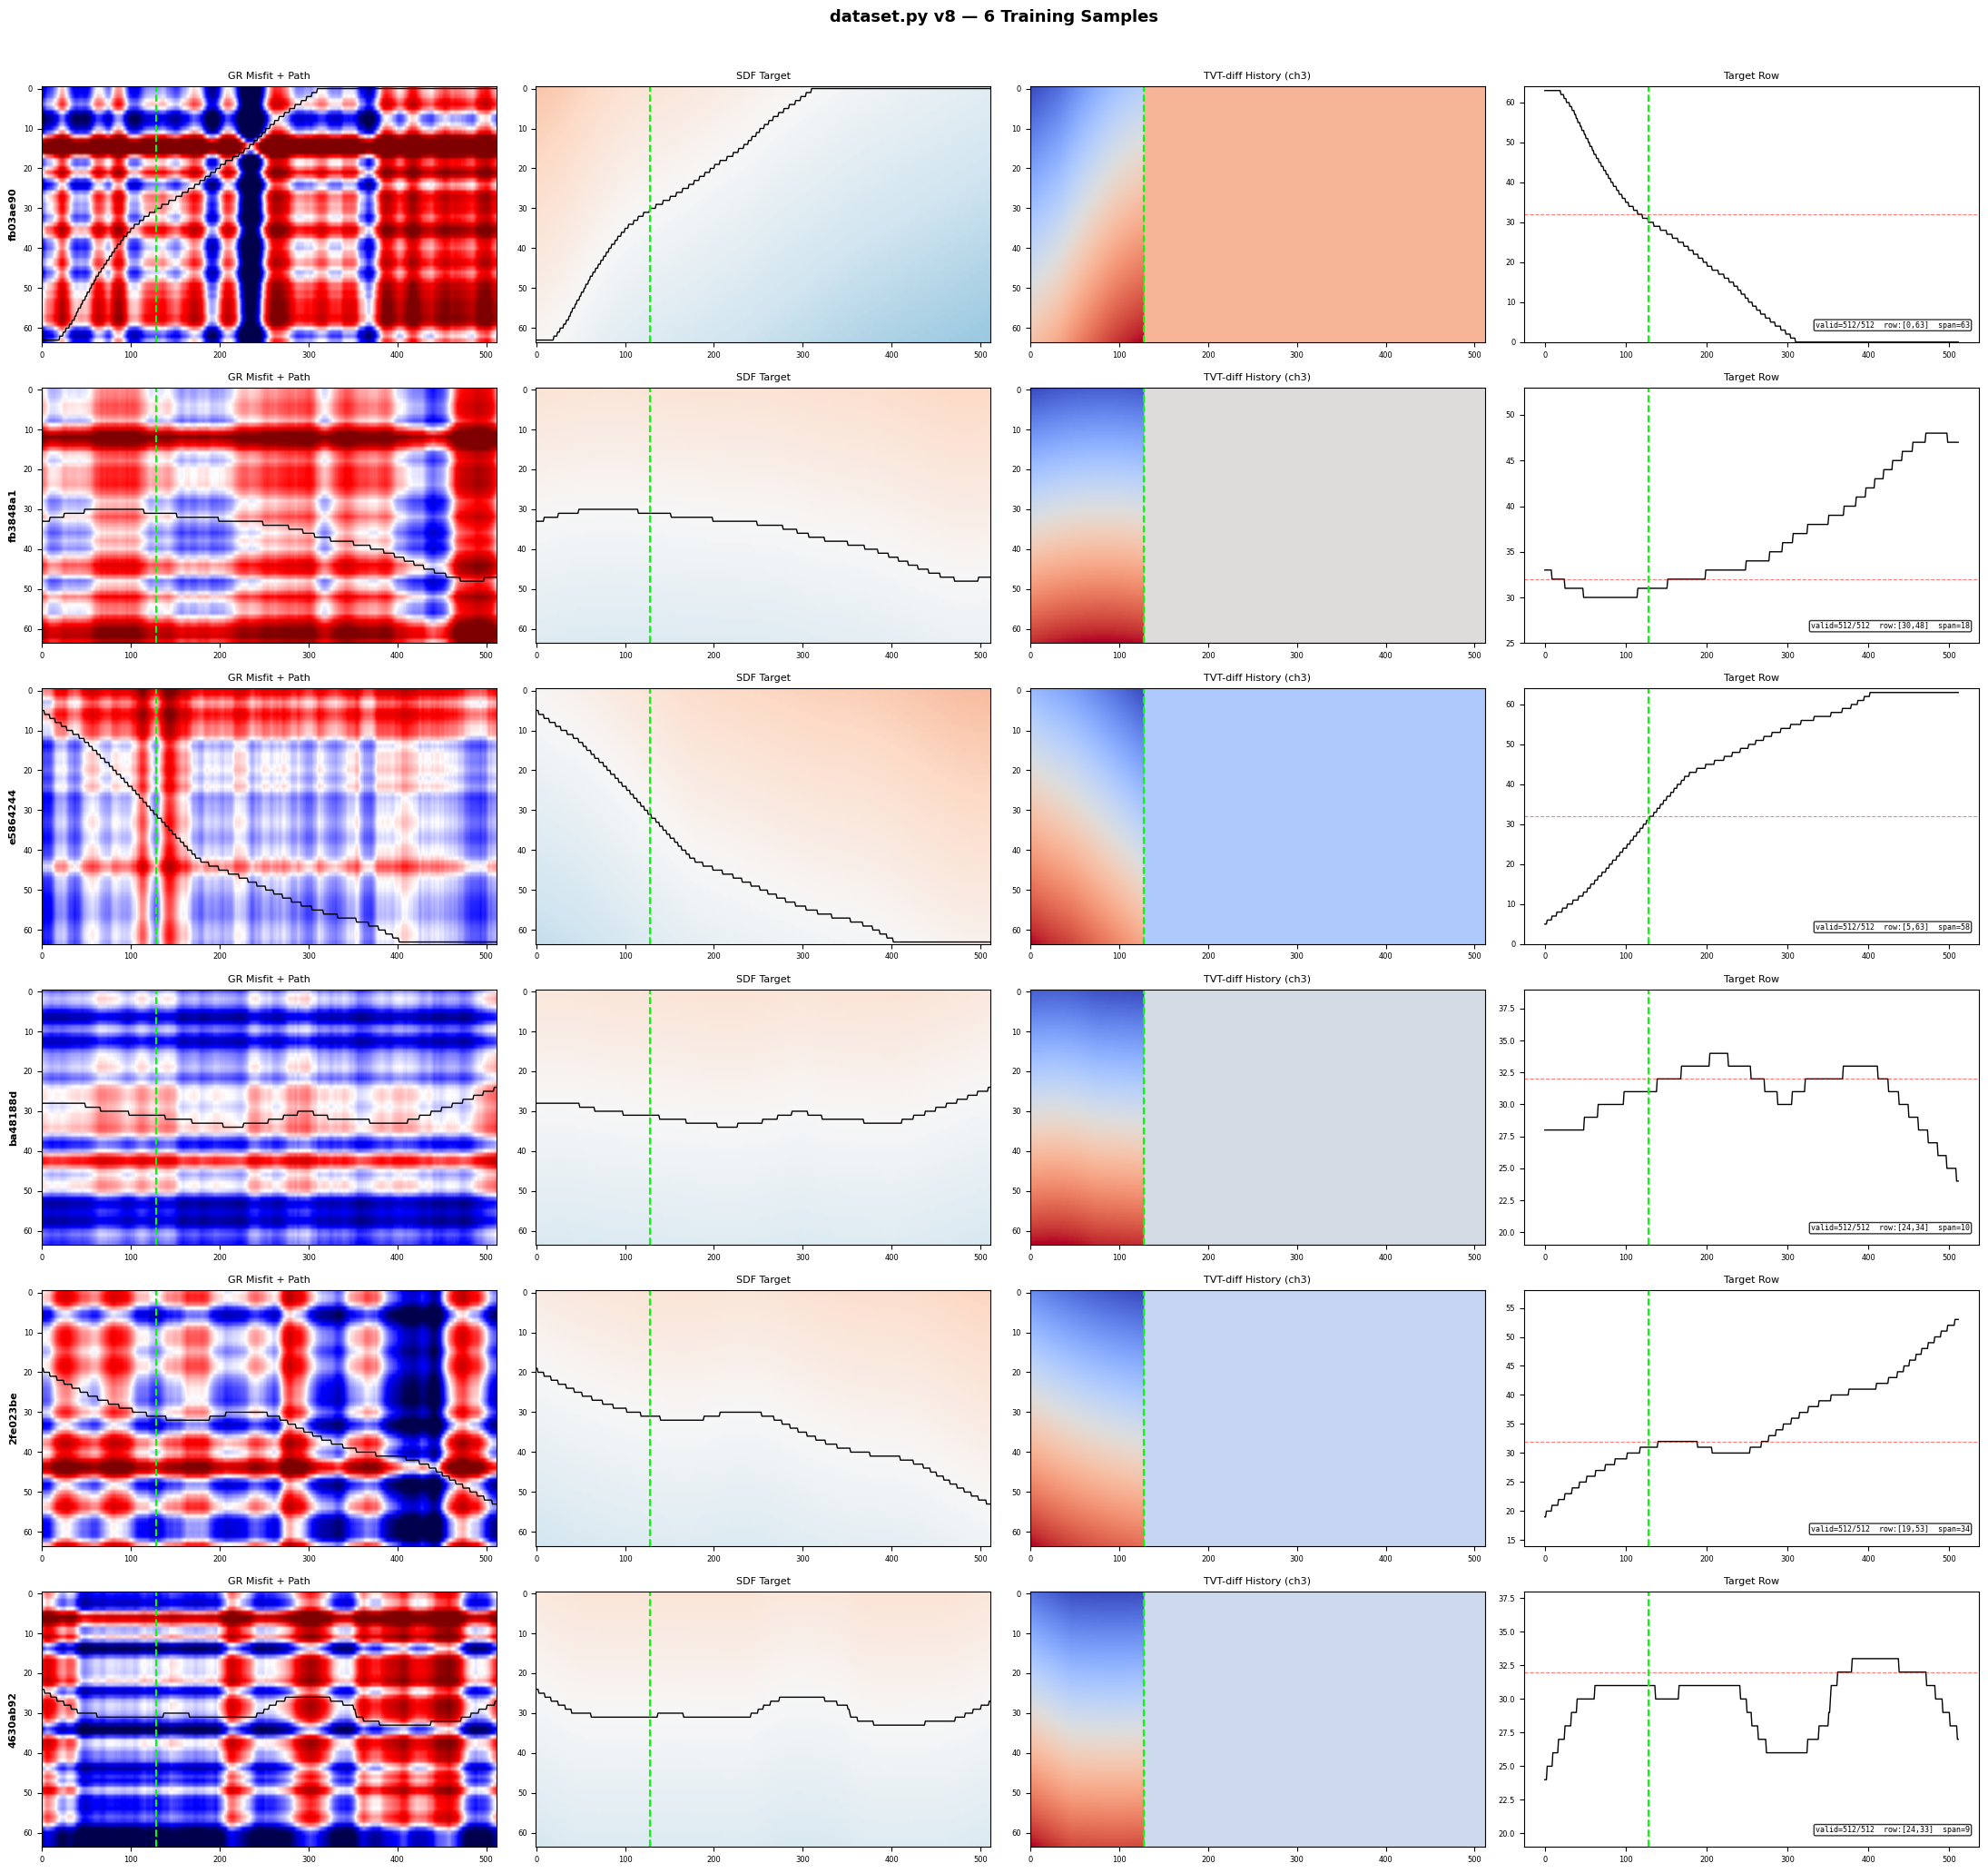

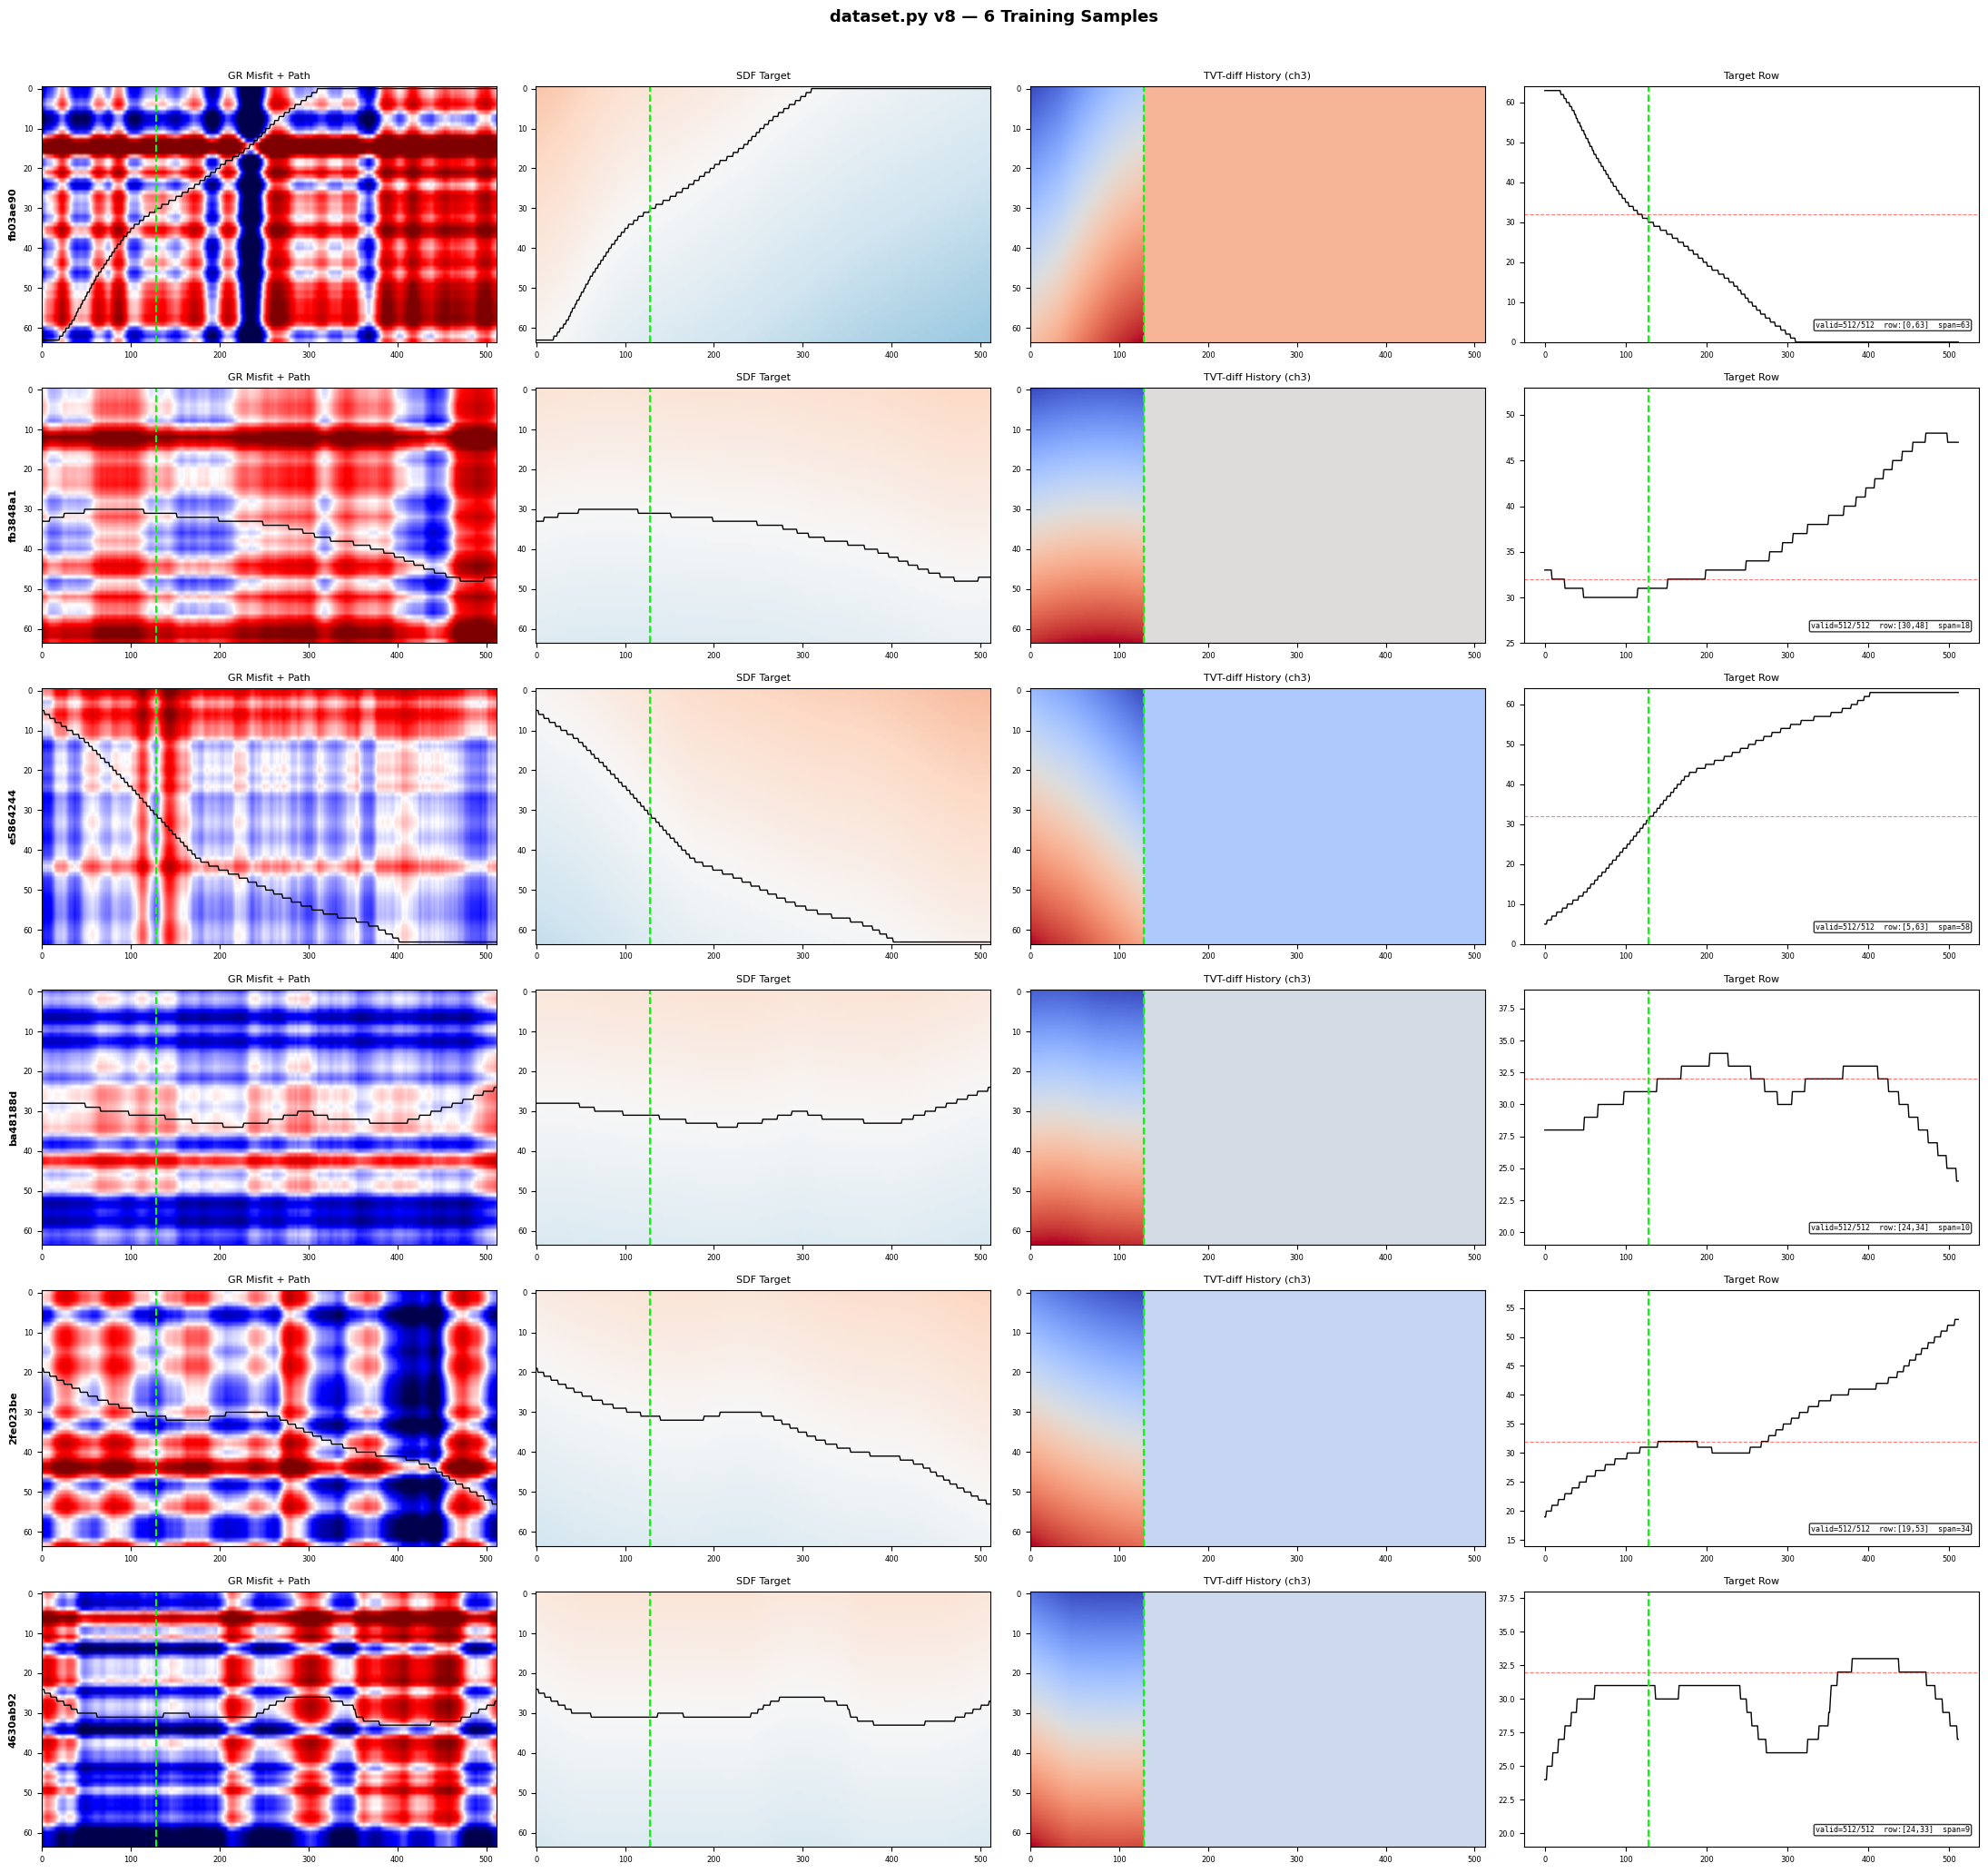

In [4]:
from src.dataset import build_sample, plot_well_row, T_TOTAL, H_TOTAL, H_H, T_H, KAGGLE_DIR
import matplotlib.pyplot as plt
import numpy as np
import glob, os

all_hw = sorted(glob.glob(f"{KAGGLE_DIR}/train/*__horizontal_well.csv"))
all_ids = [os.path.basename(f).replace("__horizontal_well.csv", "") for f in all_hw]
chosen = np.random.choice(all_ids, size=6, replace=False)

fig, axes = plt.subplots(6, 4, figsize=(22, 21))
for i, wid in enumerate(chosen):
    try:
        s = build_sample(wid, split="train")
        plot_well_row(s, wid, axes[i])
    except Exception as e:
        print(f"✗ {wid}: {e}")

fig.suptitle("dataset.py v8 — 6 Training Samples", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
fig  # <-- Jupyter displays the last expression in a cell

# CNN Model

In [5]:
%%writefile /kaggle/working/src/model_sdf_mtp.py

"""
src/model_sdf_mtp_v9.py
========================
GeoSteerMTPNet v9: CNN U-Net + SDF + MTP

Changes from v6:
  - 5-channel image built in forward() from 1D vectors:
      ch0: typewell GR broadcast
      ch1: horizontal GR broadcast
      ch2: GR misfit (t_gr - h_gr)
      ch3: TVT-diff history (t_tvt - h_tvt_history) * mask
      ch4: history validity mask
  - InstanceNorm2d(5) on input image
  - GroupNorm replaces BatchNorm (stable at batch_size 1-2)
  - Uniform masked MSE loss (no proximity weighting)
  - Spatial layout: (B, C, T, H) = (B, C, 64, 512)
  - K=5 modes; inference returns top-3 + mean(4th,5th)

Output dict:
    training  : {"loss": scalar}
    inference : {"sdf_pred": (B,K,T,H), "logit": (B,K), "pred_rows": (B,4,H)}
"""

import sys
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import CFG
from src.dataset import T_TOTAL, H_TOTAL, H_H

NUM_GROUPS = 8  # for GroupNorm; divides 32, 64, 128, 256 cleanly


# ─────────────────────────────────────────────────────────────────────────────
# Building blocks (GroupNorm variant)
# ─────────────────────────────────────────────────────────────────────────────

class ConvGnRelu(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=kernel_size,
                      padding=padding, bias=False),
            nn.GroupNorm(NUM_GROUPS, out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvGnRelu(in_ch, out_ch)
        self.conv2 = ConvGnRelu(out_ch, out_ch)
        self.proj  = (nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False)
                      if in_ch != out_ch else nn.Identity())

    def forward(self, x):
        return F.relu(self.conv2(self.conv1(x)) + self.proj(x), inplace=True)


class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.res  = ResidualBlock(in_ch, out_ch)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        skip = self.res(x)
        return skip, self.pool(skip)


class UpBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.res = ResidualBlock(in_ch, out_ch)

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[2:],
                          mode="bilinear", align_corners=False)
        return self.res(torch.cat([x, skip], dim=1))


# ─────────────────────────────────────────────────────────────────────────────
# GeoSteerMTPNet v9
# ─────────────────────────────────────────────────────────────────────────────

class GeoSteerMTPNet(nn.Module):
    """
    U-Net with K SDF output modes + logit head.

    Input  : batch dict with 1D vectors from v9 dataset
    Output : dict with 'loss' (train) or 'sdf_pred','logit','pred_rows' (eval)
    """

    def __init__(self,
                 in_ch   : int   = 5,
                 base_ch : int   = 32,
                 K       : int   = 5,
                 alpha   : float = 0.1,
                 diversity_lambda : float = 0.1):
        super().__init__()
        b = base_ch
        self.K     = K
        self.alpha = alpha
        self.diversity_lambda = diversity_lambda

        # ── Input normalization ───────────────────────────────────────────
        self.norm = nn.InstanceNorm2d(in_ch, affine=True)

        # ── Encoder ───────────────────────────────────────────────────────
        self.stem  = ConvGnRelu(in_ch, b, kernel_size=5, padding=2)
        self.down1 = DownBlock(b,     b * 2)   # /2
        self.down2 = DownBlock(b * 2, b * 4)   # /4
        self.down3 = DownBlock(b * 4, b * 8)   # /8

        # ── Bottleneck ────────────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            ResidualBlock(b * 8, b * 8),
            ResidualBlock(b * 8, b * 8),
        )

        # ── Decoder ───────────────────────────────────────────────────────
        self.up3 = UpBlock(b * 8 + b * 8, b * 4)
        self.up2 = UpBlock(b * 4 + b * 4, b * 2)
        self.up1 = UpBlock(b * 2 + b * 2, b)

        # ── SDF head: K channels, one per mode ───────────────────────────
        self.sdf_head = nn.Conv2d(b, K, kernel_size=1)

        # ── Logit head: GAP from bottleneck → K logits ───────────────────
        self.logit_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(b * 8, b * 4),
            nn.ReLU(inplace=True),
            nn.Linear(b * 4, K),
        )

        self._init_weights()

    # ── Weight init ──────────────────────────────────────────────────────

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out",
                                        nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode="fan_in",
                                        nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

        # SDF head: small init + per-channel perturbation to break symmetry
        with torch.no_grad():
            nn.init.normal_(self.sdf_head.weight, std=0.05)
            nn.init.zeros_(self.sdf_head.bias)
            self.sdf_head.weight.add_(
                torch.randn_like(self.sdf_head.weight) * 0.02
            )

    # ── Build 5-channel image from batch 1D vectors ─────────────────────

    @staticmethod
    def _build_image(batch):
        """
        Construct (B, 5, T, H) image from 1D dataset fields.

        Channels:
            0: typewell GR   — broadcast across H
            1: horizontal GR — broadcast across T
            2: GR misfit     — (t_gr - h_gr)
            3: TVT-diff hist — (t_tvt - h_tvt_history) * h_history_mask
            4: history mask  — broadcast across T
        """
        t_gr           = batch["t_gr"]            # (B, T)
        h_gr           = batch["h_gr"]            # (B, H)
        t_tvt          = batch["t_tvt"]           # (B, T)
        h_tvt_history  = batch["h_tvt_history"]   # (B, H)
        h_history_mask = batch["h_history_mask"]  # (B, H)

        B = t_gr.shape[0]
        T = t_gr.shape[1]   # T_TOTAL = 64
        H = h_gr.shape[1]   # H_TOTAL = 512

        # Broadcast 1D → 2D  (B, 1, T, H)
        t_gr_2d = t_gr.reshape(B, 1, T, 1).expand(B, 1, T, H)
        h_gr_2d = h_gr.reshape(B, 1, 1, H).expand(B, 1, T, H)

        # ch3: TVT-diff history
        tvt_diff = (
            t_tvt.reshape(B, 1, T, 1).expand(B, 1, T, H)
            - h_tvt_history.reshape(B, 1, 1, H).expand(B, 1, T, H)
        )
        mask_2d = h_history_mask.reshape(B, 1, 1, H).expand(B, 1, T, H)
        tvt_diff = tvt_diff * mask_2d

        # 5-channel image: (B, 5, T, H)
        image = torch.cat([
            t_gr_2d,              # ch0
            h_gr_2d,              # ch1
            t_gr_2d - h_gr_2d,   # ch2: GR misfit
            tvt_diff,             # ch3: TVT-diff history
            mask_2d,              # ch4: validity mask
        ], dim=1)

        return image

    # ── Forward pass ─────────────────────────────────────────────────────

    def forward(self, batch: dict) -> dict:
        # Build & normalize input image
        image = self._build_image(batch)       # (B, 5, T, H)
        x = self.norm(image)                   # InstanceNorm per channel

        # Encoder
        x = self.stem(x)
        skip1, x = self.down1(x)
        skip2, x = self.down2(x)
        skip3, x = self.down3(x)

        # Bottleneck
        b_feat = self.bottleneck(x)            # (B, 8b, T/8, H/8)

        # Logit head
        logit = self.logit_head(b_feat)        # (B, K)

        # Decoder
        d = self.up3(b_feat, skip3)
        d = self.up2(d, skip2)
        d = self.up1(d, skip1)

        # K SDF outputs
        sdf_pred = self.sdf_head(d)            # (B, K, T, H)

        # ── Always compute loss when targets available ────
        out = {}
        if "sdf" in batch:
            out["loss"] = self._loss(sdf_pred, logit, batch["sdf"], batch["h_mask"], batch["t_mask"])

        # ── Training: return loss only ───────────────────────────────────
        if self.training:
            return out

        out["sdf_pred"]  = sdf_pred
        out["logit"]     = logit
        out["pred_rows"] = self._predict_paths(sdf_pred, logit)
        return out

        # ── Inference: return predictions ────────────────────────────────
        pred_rows = self._predict_paths(sdf_pred, logit)  # (B, 4, H)

        return {
            "sdf_pred"  : sdf_pred,            # (B, K, T, H)
            "logit"     : logit,               # (B, K)
            "pred_rows" : pred_rows,           # (B, 4, H)
        }

    # ── Loss ─────────────────────────────────────────────────────────────

    def _loss(self,
              sdf_pred : torch.Tensor,   # (B, K, T, H)
              logit    : torch.Tensor,   # (B, K)
              sdf_true : torch.Tensor,   # (B, 1, T, H)
              h_mask   : torch.Tensor,   # (B, H)
              t_mask   : torch.Tensor,   # (B, T)
              ) -> torch.Tensor:
        """
        Winner-take-all MTP loss on per-mode SDFs.
        Uniform masked MSE (no proximity weighting).
        """
        B, K, T, H = sdf_pred.shape

        # Validity mask: (B, 1, T, H)
        mask_2d = (h_mask[:, None, None, :] * t_mask[:, None, :, None])

        # Per-mode MSE, masked and mean-reduced over (T, H)
        diff = (sdf_pred - sdf_true) ** 2          # (B, K, T, H)
        n_valid = mask_2d.sum(dim=(2, 3)).clamp(min=1.0)  # (B, 1)
        error = (mask_2d * diff).sum(dim=(2, 3)) / n_valid # (B, K)

        # Winner-take-all: best mode per sample
        best_k = error.argmin(dim=1)               # (B,)

        # Regression loss: only backprop through winner
        reg_loss = error[torch.arange(B, device=error.device), best_k].mean()

        # Classification loss: teach logit head which mode wins
        cls_loss = F.cross_entropy(logit, best_k)

        # Diversity penalty: push non-winner modes apart from winner
        div_loss = self._diversity_loss(sdf_pred, best_k, mask_2d, n_valid)

        return reg_loss + self.alpha * cls_loss 

    def _diversity_loss(self, sdf_pred, best_k, mask_2d, n_valid):
        """
        Encourage non-winner modes to differ from the winner.
        Penalizes similarity (negative of pairwise distance).
        SDF values clamped to ±3 to prevent divergence.
        """
        B, K, T, H = sdf_pred.shape
        sdf_clamped = sdf_pred.clamp(-3, 3)

        # Winner SDF: (B, 1, T, H)
        winner_sdf = sdf_clamped[
            torch.arange(B, device=sdf_pred.device), best_k
        ].unsqueeze(1)

        # Mean squared distance from each mode to winner
        dist = ((sdf_clamped - winner_sdf) ** 2 * mask_2d).sum(dim=(2, 3)) / n_valid
        # (B, K) — zero for winner mode, positive for others

        # We want non-winner modes to be far from winner → minimize -dist
        # Mask out the winner column
        mode_mask = torch.ones(B, K, device=sdf_pred.device)
        mode_mask[torch.arange(B), best_k] = 0.0

        # Negative mean distance of non-winners (lower = less diverse = penalized)
        non_winner_dist = (dist * mode_mask).sum(dim=1) / mode_mask.sum(dim=1).clamp(min=1)
        return -non_winner_dist.mean()

    # ── Inference: top-3 prob paths + mean of 4th & 5th ──────────────────

    @torch.no_grad()
    def _predict_paths(self, sdf_pred, logit):
        """
        Returns (B, 4, H) predicted boundary rows:
            path 0: highest-prob mode
            path 1: 2nd-highest-prob mode
            path 2: 3rd-highest-prob mode
            path 3: mean of 4th + 5th prob modes
        """
        B, K, T, H = sdf_pred.shape

        # Per-mode boundary: argmin |SDF| along T axis → (B, K, H)
        per_mode_rows = torch.abs(sdf_pred).argmin(dim=2).float()

        # Sort modes by probability (descending)
        prob = F.softmax(logit, dim=1)             # (B, K)
        sorted_idx = prob.argsort(dim=1, descending=True)  # (B, K)

        # Gather per-mode rows in sorted order: (B, K, H)
        idx_expand = sorted_idx.unsqueeze(-1).expand(B, K, H)
        sorted_rows = torch.gather(per_mode_rows, 1, idx_expand)

        # Top-3 individual + mean of 4th & 5th
        top3 = sorted_rows[:, :3, :]              # (B, 3, H)
        tail_mean = sorted_rows[:, 3:5, :].mean(dim=1, keepdim=True)  # (B, 1, H)

        pred_rows = torch.cat([top3, tail_mean], dim=1)  # (B, 4, H)
        return pred_rows


# ─────────────────────────────────────────────────────────────────────────────
# Model factory
# ─────────────────────────────────────────────────────────────────────────────

def build_model(rank: int = 0) -> GeoSteerMTPNet:
    device = torch.device(
        f"cuda:{rank}" if torch.cuda.is_available() else "cpu"
    )
    model = GeoSteerMTPNet(
        in_ch    = 5,
        base_ch  = getattr(CFG, "SDF_MTP_BASE_CH", 32),
        K        = getattr(CFG, "SDF_MTP_K", 5),
        alpha    = getattr(CFG, "SDF_MTP_ALPHA", 0.1),
        diversity_lambda = getattr(CFG, "SDF_MTP_DIVERSITY", 0.1),
    ).to(device)
    n = sum(p.numel() for p in model.parameters())
    print(f"  GeoSteerMTPNet v9: {n:,} params  "
          f"(K={model.K}, base_ch={model.stem.block[0].out_channels}, "
          f"device={device})")
    return model


# ─────────────────────────────────────────────────────────────────────────────
# Verification
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    import numpy as np

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n{'='*60}")
    print(f"  model_sdf_mtp_v9.py — verification")
    print(f"  Device: {device}")
    print(f"{'='*60}\n")

    B, K = 2, 5
    T, H = T_TOTAL, H_TOTAL

    # ── Synthetic batch matching v9 dataset output ──
    batch = {
        "t_gr"          : torch.randn(B, T),
        "h_gr"          : torch.randn(B, H),
        "t_tvt"         : torch.randn(B, T) * 100 + 11000,
        "h_tvt"         : torch.randn(B, H) * 100 + 11000,
        "h_tvt_history" : torch.randn(B, H) * 100 + 11000,
        "h_mask"        : torch.ones(B, H),
        "h_history_mask": torch.ones(B, H),
        "t_mask"        : torch.ones(B, T),
        "sdf"           : torch.randn(B, 1, T, H) * 0.5,
        "target"        : torch.randint(0, T, (B, H)),
    }
    # Zero out future in history fields
    batch["h_history_mask"][:, H_H:] = 0.0
    batch["h_tvt_history"][:, H_H:] = 0.0

    batch_gpu = {k: v.to(device) for k, v in batch.items()}

    # ── Step 1: Build image ──
    print("STEP 1: Image construction...")
    image = GeoSteerMTPNet._build_image(batch_gpu)
    assert image.shape == (B, 5, T, H), f"image: {image.shape}"
    print(f"  ✓ image shape: {tuple(image.shape)} = (B, 5, T={T}, H={H})")

    # Verify ch4 (mask) is zero in future columns
    assert (image[:, 4, :, H_H:] == 0).all(), "mask channel leaks into future"
    print(f"  ✓ mask channel zero after col {H_H}")

    # ── Step 2: Forward (train mode) ──
    print("\nSTEP 2: Forward pass (train)...")
    net = GeoSteerMTPNet(K=K).to(device)
    n = sum(p.numel() for p in net.parameters())
    print(f"  Parameters: {n:,}")

    net.train()
    out = net(batch_gpu)
    assert "loss" in out, "train mode should return 'loss'"
    assert torch.isfinite(out["loss"]), f"loss not finite: {out['loss']}"
    print(f"  ✓ loss = {out['loss'].item():.4f}")

    # ── Step 3: Backward ──
    print("\nSTEP 3: Backward pass...")
    out["loss"].backward()
    grads_ok = all(
        p.grad is not None and torch.isfinite(p.grad).all()
        for p in net.parameters() if p.requires_grad
    )
    assert grads_ok, "Some gradients are None or non-finite"
    print(f"  ✓ All gradients finite")

    # ── Step 4: Forward (eval mode) ──
    print("\nSTEP 4: Forward pass (eval)...")
    net.eval()
    with torch.no_grad():
        out = net(batch_gpu)
    assert out["sdf_pred"].shape == (B, K, T, H), f"sdf: {out['sdf_pred'].shape}"
    assert out["logit"].shape == (B, K), f"logit: {out['logit'].shape}"
    assert out["pred_rows"].shape == (B, 4, H), f"pred_rows: {out['pred_rows'].shape}"
    print(f"  ✓ sdf_pred : {tuple(out['sdf_pred'].shape)}")
    print(f"  ✓ logit    : {tuple(out['logit'].shape)}")
    print(f"  ✓ pred_rows: {tuple(out['pred_rows'].shape)} = (B, 4, H)")

    # ── Step 5: pred_rows range check ──
    print("\nSTEP 5: Prediction sanity...")
    rows = out["pred_rows"]
    print(f"  pred_rows range: [{rows.min():.1f}, {rows.max():.1f}] "
          f"(should be in [0, {T-1}])")
    assert rows.min() >= 0 and rows.max() < T
    print(f"  ✓ All predictions in valid row range")

    # ── Step 6: Mode diversity ──
    print("\nSTEP 6: Mode diversity (after init)...")
    sdf_np = out["sdf_pred"][0].cpu().numpy()
    diffs = []
    for i in range(K):
        for j in range(i + 1, K):
            diffs.append(np.abs(sdf_np[i] - sdf_np[j]).mean())
    mean_diff = np.mean(diffs)
    print(f"  Mean pairwise |SDF_i - SDF_j| = {mean_diff:.4f}")
    if mean_diff < 0.01:
        print("  ⚠  Modes may be collapsing")
    else:
        print(f"  ✓ Symmetry broken")

    # ── Step 7: Divisibility check ──
    print(f"\nSTEP 7: Spatial divisibility...")
    print(f"  T={T}: T/8 = {T/8} {'✓' if T % 8 == 0 else '✗'}")
    print(f"  H={H}: H/8 = {H/8} {'✓' if H % 8 == 0 else '✗'}")

    print(f"\n{'='*60}")
    print(f"  ✓ model_sdf_mtp_v9.py verification PASSED")
    print(f"{'='*60}\n")

Writing /kaggle/working/src/model_sdf_mtp.py


In [6]:
%%writefile /kaggle/working/src/model_mtp.py
"""
src/model_mtp.py
================
GeoStirringNet: CNN + FC multi-trajectory prediction model.

Predicts K candidate boundary trajectories + mode logits from a
(heatmap, history) image pair.

Improvements over the reference implementation:
- Residual connections in CNN blocks
- Proper dropout (configurable, not Dropout(0))
- Dynamic flat_size computation (no hardcoded magic number)
- Kaiming weight initialization
- Batch-dict interface matching GeoSteerNet for engine compatibility
- Returns unified keys: "loss", "pred_rows", "path", "logit"
"""

import sys
import os
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import CFG
from src.dataset import (
    GeoSteerDataset, load_well_data, build_sample,
    T_TOTAL, H_TOTAL, H_BEFORE_PS, S,
)


# ─────────────────────────────────────────────────────────────────────────────
# Building blocks
# ─────────────────────────────────────────────────────────────────────────────

class ConvBlock(nn.Module):
    """Conv2d → BatchNorm → GELU with optional residual shortcut."""

    def __init__(self, c_in: int, c_out: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.GELU(),
        )
        # Residual projection when channels change
        self.shortcut = (
            nn.Conv2d(c_in, c_out, kernel_size=1, bias=False)
            if c_in != c_out else nn.Identity()
        )

    def forward(self, x):
        return self.conv(x) + self.shortcut(x)


# ─────────────────────────────────────────────────────────────────────────────
# GeoStirringNet  (Multi-Trajectory Prediction)
# ─────────────────────────────────────────────────────────────────────────────

class GeoStirringNet(nn.Module):
    """
    Input  : batch dict with 'heatmap' (B,1,T,H) and 'history' (B,1,T,H)
    Output : dict with 'loss', 'pred_rows' (B,H), 'path' (B,K,H), 'logit' (B,K)

    Architecture:
        CNN encoder: 2ch → 8 → 16 → 32 → 96 with 3 AvgPool2d(2)
        FC head: flat → 512 → 1024 → 4096
        Path head: 4096 → K*L  (K trajectories of length L)
        Logit head: 4096 → K   (mode probabilities)
    """

    def __init__(self,
                 K: int = 10,
                 alpha: float = 1.0,
                 dropout: float = 0.1):
        super().__init__()
        self.K     = K
        self.L     = H_TOTAL   # trajectory length = number of lateral columns
        self.alpha = alpha

        # ── CNN encoder ───────────────────────────────────────────────────
        self.cnn = nn.Sequential(
            ConvBlock(2, 8),
            ConvBlock(8, 8),
            nn.AvgPool2d(kernel_size=2, stride=2),
            ConvBlock(8, 16),
            ConvBlock(16, 16),
            nn.AvgPool2d(kernel_size=2, stride=2),
            ConvBlock(16, 32),
            ConvBlock(32, 32),
            nn.AvgPool2d(kernel_size=2, stride=2),
            ConvBlock(32, 96),
            ConvBlock(96, 96),
        )

        # ── Compute flat_size dynamically ─────────────────────────────────
        with torch.no_grad():
            dummy = torch.zeros(1, 2, T_TOTAL, H_TOTAL)
            flat_size = self.cnn(dummy).view(1, -1).shape[1]
        self._flat_size = flat_size

        # ── FC head ───────────────────────────────────────────────────────
        self.head = nn.Sequential(
            nn.Linear(flat_size, 512, bias=False),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 1024, bias=False),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(1024, 4096, bias=False),
            nn.BatchNorm1d(4096),
            nn.GELU(),
        )

        # ── Output heads ─────────────────────────────────────────────────
        self.path_head  = nn.Linear(4096, self.K * self.L)
        self.logit_head = nn.Linear(4096, self.K)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out",
                                        nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d) or isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode="fan_in",
                                        nonlinearity="linear")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, batch: dict) -> dict:
        heatmap = batch["heatmap"]   # (B, 1, T, H)
        history = batch["history"]   # (B, 1, T, H)

        x = torch.cat([heatmap, history], dim=1)   # (B, 2, T, H)
        x = self.cnn(x)                             # (B, 96, T//8, H//8)
        flat = x.reshape(x.size(0), -1)             # (B, flat_size)
        h = self.head(flat)                          # (B, 4096)

        path  = self.path_head(h).view(-1, self.K, self.L)  # (B, K, H)
        logit = self.logit_head(h)                            # (B, K)

        # ── Predicted boundary rows (prob-weighted average) ───────────────
        prob = F.softmax(logit, dim=1)                        # (B, K)
        pred_rows = (path * prob.unsqueeze(-1)).sum(dim=1)    # (B, H)

        output = {
            "pred_rows" : pred_rows,
            "path"      : path,
            "logit"     : logit,
        }

        # ── Loss ──────────────────────────────────────────────────────────
        if "matched" in batch:
            target = batch["matched"]   # (B, H) raw row indices
            output["loss"] = mtp_loss(
                path, logit, target, alpha=self.alpha
            )

        return output


# ─────────────────────────────────────────────────────────────────────────────
# MTP Loss
# ─────────────────────────────────────────────────────────────────────────────

def mtp_loss(pred: torch.Tensor,
             logit: torch.Tensor,
             target: torch.Tensor,
             alpha: float = 0.1) -> torch.Tensor:
    """
    Multi-trajectory prediction loss with winner-take-all assignment.
    Uses L1 (MAE) norm per Alyaev & Elsheikh (2022), Eq. 8 and 10.

    pred   : (B, K, H)  K candidate trajectories
    logit  : (B, K)     mode logits (pre-softmax)
    target : (B, H)     ground truth boundary row indices
    alpha  : weight for the classification loss term

    Loss = I_reg + alpha * I_class
         = MAE(best_mode, target) + alpha * CrossEntropy(logit, best_mode)
    """
    B, K, H = pred.shape
    gt = target[:, None, :]                      # (B, 1, H)

    # Per-mode MAE: (B, K)  — L1 norm, length-normalized (Eq. 10)
    error = torch.abs(pred - gt).mean(dim=-1)

    # Winner-take-all: best mode per sample (Eq. 8)
    best_k = error.argmin(dim=1)                 # (B,)

    # Regression loss: only backprop through the best mode
    reg_loss = error[torch.arange(B, device=pred.device), best_k].mean()

    # Classification loss: teach logit head to predict which mode wins (Eq. 9)
    cls_loss = F.cross_entropy(logit, best_k)

    return reg_loss + alpha * cls_loss


# ─────────────────────────────────────────────────────────────────────────────
# Model factory
# ─────────────────────────────────────────────────────────────────────────────

def build_mtp_model(rank: int) -> GeoStirringNet:
    """Construct and move GeoStirringNet to the correct device."""
    device = torch.device(
        f"cuda:{rank}" if torch.cuda.is_available() else "cpu"
    )
    model = GeoStirringNet(
        K       = CFG.MTP_K,
        alpha   = CFG.MTP_ALPHA,
        dropout = CFG.MTP_DROPOUT,
    ).to(device)
    n = sum(p.numel() for p in model.parameters())
    print(f"  GeoStirringNet (MTP): {n:,} parameters  "
          f"(K={CFG.MTP_K}, L={H_TOTAL}, flat_size={model._flat_size})  "
          f"(device: {device})")
    return model


# ─────────────────────────────────────────────────────────────────────────────
# Verification
# ─────────────────────────────────────────────────────────────────────────────

def verify_mtp_model(sample_id: str = "0dd99dc5"):
    """
    End-to-end check: dataset → batch → model → loss → backward.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n{'='*55}")
    print(f"  MTP Verification: dataset + model")
    print(f"  Device: {device}")
    print(f"{'='*55}\n")

    # ── Step 1: Build dataset ─────────────────────────────────────────────
    print("STEP 1: Building GeoSteerDataset (1 well, offsets [-2,0,2])...")
    ds = GeoSteerDataset(
        well_ids=[sample_id],
        offsets=[-2, 0, 2],
        split="train",
    )
    print(f"  Samples in dataset: {len(ds)}")
    assert len(ds) > 0, "Dataset is empty"
    print("  ✓ Dataset non-empty\n")

    # ── Step 2: Check shapes ──────────────────────────────────────────────
    print("STEP 2: Checking __getitem__ shapes...")
    sample = ds[0]
    expected = {
        "heatmap" : (1, T_TOTAL, H_TOTAL),
        "history" : (1, T_TOTAL, H_TOTAL),
        "sdf"     : (1, T_TOTAL, H_TOTAL),
        "matched" : (H_TOTAL,),
        "label"   : (H_TOTAL,),
        "target"  : (H_TOTAL,),
        "h_gr"    : (H_TOTAL,),
        "t_gr"    : (T_TOTAL,),
        "h_mask"  : (H_TOTAL,),
        "t_mask"  : (T_TOTAL,),
    }
    all_ok = True
    for key, shape in expected.items():
        actual = tuple(sample[key].shape)
        status = "✓" if actual == shape else "✗"
        if actual != shape:
            all_ok = False
        print(f"  {status}  {key:<10} expected {str(shape):<18} got {actual}")
    assert all_ok, "Shape mismatch"
    print("  All shapes correct\n")

    # ── Step 3: Batch ─────────────────────────────────────────────────────
    print("STEP 3: Building batch via DataLoader...")
    loader = torch.utils.data.DataLoader(ds, batch_size=len(ds), shuffle=False)
    batch = next(iter(loader))
    B = batch["heatmap"].shape[0]
    print(f"  Batch size: {B}")
    print(f"  heatmap: {tuple(batch['heatmap'].shape)}")
    print(f"  matched: {tuple(batch['matched'].shape)}")
    print("  ✓ Batch shapes correct\n")

    # ── Step 4: Forward pass ──────────────────────────────────────────────
    print("STEP 4: Forward pass through GeoStirringNet...")
    net = GeoStirringNet(
        K=CFG.MTP_K, alpha=CFG.MTP_ALPHA, dropout=CFG.MTP_DROPOUT
    ).to(device)
    n = sum(p.numel() for p in net.parameters())
    print(f"  Parameters: {n:,}")
    print(f"  Flat size : {net._flat_size}")

    batch_gpu = {k: v.to(device) for k, v in batch.items()
                 if isinstance(v, torch.Tensor)}

    with torch.no_grad():
        output = net(batch_gpu)

    print(f"  path      : {tuple(output['path'].shape)}")
    print(f"  logit     : {tuple(output['logit'].shape)}")
    print(f"  pred_rows : {tuple(output['pred_rows'].shape)}")
    print(f"  loss      : {output['loss'].item():.4f}")

    assert tuple(output["path"].shape) == (B, CFG.MTP_K, H_TOTAL)
    assert tuple(output["logit"].shape) == (B, CFG.MTP_K)
    assert tuple(output["pred_rows"].shape) == (B, H_TOTAL)
    assert torch.isfinite(output["loss"])
    print("  ✓ Output shapes correct")
    print("  ✓ Loss is finite\n")

    # ── Step 5: Backward pass ─────────────────────────────────────────────
    print("STEP 5: Backward pass (gradient check)...")
    net.train()
    output = net(batch_gpu)
    output["loss"].backward()

    grads_ok = all(
        p.grad is not None and torch.isfinite(p.grad).all()
        for p in net.parameters() if p.requires_grad
    )
    assert grads_ok, "Non-finite gradients"
    print("  ✓ All gradients finite\n")

    # ── Step 6: Sanity check pred_rows range ──────────────────────────────
    print("STEP 6: Checking pred_rows range...")
    pr = output["pred_rows"].detach()
    gt = batch_gpu["matched"]
    print(f"  pred_rows range: [{pr.min().item():.1f}, {pr.max().item():.1f}]")
    print(f"  matched   range: [{gt.min().item():.1f}, {gt.max().item():.1f}]")
    print(f"  T_TOTAL = {T_TOTAL} (expected pred_rows in ~[0, {T_TOTAL-1}])")
    print()

    print(f"{'='*55}")
    print("  All MTP checks passed.")
    print(f"{'='*55}\n")


if __name__ == "__main__":
    verify_mtp_model("0dd99dc5")

Writing /kaggle/working/src/model_mtp.py


In [7]:
%%writefile /kaggle/working/src/model_sdf.py
"""
src/model_sdf.py
================
GeoSteerNet: U-Net style encoder-decoder that predicts a Signed Distance
Function (SDF) from a (heatmap, history) image pair.

Includes a self-contained verification block at the bottom that checks
both the model and dataset.py are working correctly together.
"""

import sys
import os
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import CFG
from src.dataset import (
    GeoSteerDataset, load_well_data, build_sample,
    T_TOTAL, H_TOTAL, H_BEFORE_PS, S,
)


# ─────────────────────────────────────────────────────────────────────────────
# Building blocks
# ─────────────────────────────────────────────────────────────────────────────

class ConvBnRelu(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=kernel_size,
                      padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBnRelu(in_ch,  out_ch)
        self.conv2 = ConvBnRelu(out_ch, out_ch)
        self.proj  = (nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False)
                      if in_ch != out_ch else nn.Identity())

    def forward(self, x):
        return F.relu(self.conv2(self.conv1(x)) + self.proj(x), inplace=True)


class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.res  = ResidualBlock(in_ch, out_ch)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        skip = self.res(x)
        return skip, self.pool(skip)


class UpBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.res = ResidualBlock(in_ch, out_ch)

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[2:],
                          mode="bilinear", align_corners=False)
        return self.res(torch.cat([x, skip], dim=1))


# ─────────────────────────────────────────────────────────────────────────────
# GeoSteerNet
# ─────────────────────────────────────────────────────────────────────────────

class GeoSteerNet(nn.Module):
    """
    Input  : batch dict with 'heatmap' (B,1,64,24) and 'history' (B,1,64,24)
    Output : dict with 'sdf' (B,1,64,24) and 'sdf_loss' (scalar)
    """

    def __init__(self, base_ch: int = 32):
        super().__init__()
        b = base_ch

        self.stem = ConvBnRelu(2, b, kernel_size=5, padding=2)

        # Encoder: (64,24)→(32,12)→(16,6)→(8,3)
        self.down1 = DownBlock(b,     b * 2)
        self.down2 = DownBlock(b * 2, b * 4)
        self.down3 = DownBlock(b * 4, b * 8)

        # Bottleneck at (8,3)
        self.bottleneck = nn.Sequential(
            ResidualBlock(b * 8, b * 8),
            ResidualBlock(b * 8, b * 8),
        )

        # Decoder
        self.up3 = UpBlock(b * 8 + b * 8, b * 4)
        self.up2 = UpBlock(b * 4 + b * 4, b * 2)
        self.up1 = UpBlock(b * 2 + b * 2, b)

        # SDF head — no activation, unbounded output
        self.sdf_head = nn.Conv2d(b, 1, kernel_size=1)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out",
                                        nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        nn.init.normal_(self.sdf_head.weight, std=0.01)
        nn.init.zeros_(self.sdf_head.bias)

    def forward(self, batch: dict) -> dict:
        x = torch.cat([batch["heatmap"], batch["history"]], dim=1)

        x = self.stem(x)

        skip1, x = self.down1(x)
        skip2, x = self.down2(x)
        skip3, x = self.down3(x)

        x = self.bottleneck(x)

        x = self.up3(x, skip3)
        x = self.up2(x, skip2)
        x = self.up1(x, skip1)

        sdf_pred = self.sdf_head(x)

        out = {"sdf": sdf_pred}
        if "sdf" in batch:
            out["sdf_loss"] = self._loss(
                sdf_pred, batch["sdf"],
                batch["h_mask"], batch["t_mask"]
            )
        return out

    def _loss(self, sdf_pred, sdf_true, h_mask, t_mask):
        """
        Proximity-weighted masked MSE.
        Cells near the boundary receive higher weight so the model
        focuses on getting the zero-crossing right.
        """
        h_mask_2d = h_mask[:, None, None, :]   # (B,1,1,H)
        t_mask_2d = t_mask[:, None, :, None]   # (B,1,T,1)
        mask_2d   = h_mask_2d * t_mask_2d      # (B,1,T,H)

        proximity = torch.exp(-torch.abs(sdf_true) / 5.0)
        weight    = mask_2d * proximity

        loss = (weight * (sdf_pred - sdf_true) ** 2).sum()
        loss = loss / (weight.sum() + 1e-8)
        return loss


def build_sdf_model(rank: int, base_ch: int = 32) -> GeoSteerNet:
    """Construct and move GeoSteerNet to the correct device."""
    device = torch.device(
        f"cuda:{rank}" if torch.cuda.is_available() else "cpu"
    )
    model = GeoSteerNet(base_ch=base_ch).to(device)
    n = sum(p.numel() for p in model.parameters())
    print(f"  GeoSteerNet: {n:,} parameters  (device: {device})")
    return model


# ─────────────────────────────────────────────────────────────────────────────
# Verification
# ─────────────────────────────────────────────────────────────────────────────

def verify_model_and_dataset(sample_id: str = "0dd99dc5"):
    """
    End-to-end check: dataset → batch → model → loss.
    Verifies that dataset.py and model_sdf.py are correctly wired together.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n{'='*55}")
    print(f"  Verification: dataset + model")
    print(f"  Device: {device}")
    print(f"{'='*55}\n")

    # ── Step 1: Build a small dataset from one well ───────────────────────
    print("STEP 1: Building GeoSteerDataset (1 well, offsets [-2,0,2])...")
    ds = GeoSteerDataset(
        well_ids = [sample_id],
        offsets  = [-2, 0, 2],
        split    = "train",
    )
    print(f"  Samples in dataset : {len(ds)}")
    assert len(ds) > 0, "Dataset is empty — check well_id and offsets"
    print("  ✓ Dataset non-empty\n")

    # ── Step 2: Check one raw sample from __getitem__ ─────────────────────
    print("STEP 2: Checking __getitem__ shapes...")
    sample = ds[0]
    expected = {
        "heatmap" : (1, T_TOTAL, H_TOTAL),
        "history" : (1, T_TOTAL, H_TOTAL),
        "sdf"     : (1, T_TOTAL, H_TOTAL),
        "label"   : (H_TOTAL,),
        "target"  : (H_TOTAL,),
        "h_gr"    : (H_TOTAL,),
        "t_gr"    : (T_TOTAL,),
        "h_mask"  : (H_TOTAL,),
        "t_mask"  : (T_TOTAL,),
    }
    all_ok = True
    for key, shape in expected.items():
        actual = tuple(sample[key].shape)
        status = "✓" if actual == shape else "✗"
        if actual != shape:
            all_ok = False
        print(f"  {status}  {key:<10} expected {str(shape):<18} got {actual}")
    assert all_ok, "Shape mismatch in __getitem__ output"
    print("  All shapes correct\n")

    # ── Step 3: Stack into a batch of 4 ──────────────────────────────────
    print("STEP 3: Building a batch of 4 via DataLoader...")
    loader = torch.utils.data.DataLoader(ds, batch_size=len(ds), shuffle=False)
    batch  = next(iter(loader))
    print(f"  heatmap batch shape : {tuple(batch['heatmap'].shape)}")
    print(f"  history batch shape : {tuple(batch['history'].shape)}")
    print(f"  sdf     batch shape : {tuple(batch['sdf'].shape)}")
    assert tuple(batch["heatmap"].shape) == (len(ds), 1, T_TOTAL, H_TOTAL), \
        "Unexpected heatmap batch shape"
    print("  ✓ Batch shapes correct\n")

    # ── Step 4: Forward pass through GeoSteerNet ─────────────────────────
    print("STEP 4: Forward pass through GeoSteerNet...")
    net = GeoSteerNet(base_ch=CFG.SDF_BASE_CH).to(device)
    n   = sum(p.numel() for p in net.parameters())
    print(f"  Parameters: {n:,}")

    batch_gpu = {k: v.to(device) for k, v in batch.items()
                 if isinstance(v, torch.Tensor)}

    with torch.no_grad():
        output = net(batch_gpu)

    print(f"  sdf output shape : {tuple(output['sdf'].shape)}")
    print(f"  sdf_loss         : {output['sdf_loss'].item():.4f}")

    assert tuple(output["sdf"].shape) == (len(ds), 1, T_TOTAL, H_TOTAL), \
        "Unexpected SDF output shape"
    assert torch.isfinite(output["sdf_loss"]), \
        "Loss is not finite"
    print("  ✓ Output shape correct")
    print("  ✓ Loss is finite\n")

    # ── Step 5: Backward pass ─────────────────────────────────────────────
    print("STEP 5: Backward pass (gradient check)...")
    net.train()
    output = net(batch_gpu)
    output["sdf_loss"].backward()

    # Check that at least one parameter received a gradient
    grads_ok = all(
        p.grad is not None and torch.isfinite(p.grad).all()
        for p in net.parameters() if p.requires_grad
    )
    assert grads_ok, "Some parameters have missing or non-finite gradients"
    print("  ✓ All gradients finite\n")

    print(f"{'='*55}")
    print("  All checks passed — dataset and model are correctly wired.")
    print(f"{'='*55}\n")


if __name__ == "__main__":
    verify_model_and_dataset("0dd99dc5")

Writing /kaggle/working/src/model_sdf.py


# Model Debugging

In [8]:
!cd /kaggle/working && python src/model_sdf_mtp.py


  model_sdf_mtp_v9.py — verification
  Device: cuda

STEP 1: Image construction...
  ✓ image shape: (2, 5, 64, 512) = (B, 5, T=64, H=512)
  ✓ mask channel zero after col 128

STEP 2: Forward pass (train)...
  Parameters: 4,659,732
  ✓ loss = 1.2956

STEP 3: Backward pass...
  ✓ All gradients finite

STEP 4: Forward pass (eval)...
  ✓ sdf_pred : (2, 5, 64, 512)
  ✓ logit    : (2, 5)
  ✓ pred_rows: (2, 4, 512) = (B, 4, H)

STEP 5: Prediction sanity...
  pred_rows range: [0.0, 63.0] (should be in [0, 63])
  ✓ All predictions in valid row range

STEP 6: Mode diversity (after init)...
  Mean pairwise |SDF_i - SDF_j| = 2.7925
  ✓ Symmetry broken

STEP 7: Spatial divisibility...
  T=64: T/8 = 8.0 ✓
  H=512: H/8 = 64.0 ✓

  ✓ model_sdf_mtp_v9.py verification PASSED



# Engine

In [9]:
%%writefile /kaggle/working/src/engine.py
"""
src/engine.py  (v9)
===================
Training engine for GeoSteerMTPNet v9.

Changes from v8:
  - Model factory imports from model_sdf_mtp_v9
  - make_loader: no noise_pct parameter
  - row_rmse: handles (B, 4, H) pred_rows — reports top-1 and oracle-best
  - valid_epoch: model eval mode now returns both loss and predictions
"""

import sys
import os
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import gc
import copy
import contextlib

import numpy as np
import torch
import torch.nn as nn
from torch.nn.parallel import DistributedDataParallel as DDP
import torch.distributed as dist
from torch.utils.data.distributed import DistributedSampler

try:
    import wandb
    from kaggle_secrets import UserSecretsClient
    HAS_WANDB = True
except ImportError:
    HAS_WANDB = False

from src.config import CFG, RUN_VERSION, PROJECT_NAME, set_seed
from src.dataset import GeoSteerDataset, make_loader, T_TOTAL, H_TOTAL


# ─────────────────────────────────────────────────────────────────────────────
# MODEL FACTORY
# ─────────────────────────────────────────────────────────────────────────────

def build_model(rank: int):
    """Build the model based on CFG.MODEL_TYPE."""
    if CFG.MODEL_TYPE == "sdf_mtp":
        from src.model_sdf_mtp import build_model as _build
        return _build(rank)
    else:
        raise ValueError(f"Unknown MODEL_TYPE: {CFG.MODEL_TYPE}")


# ─────────────────────────────────────────────────────────────────────────────
# HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _resolve_device(rank: int) -> torch.device:
    if torch.cuda.is_available():
        return torch.device(f"cuda:{rank}")
    return torch.device("cpu")


# ─────────────────────────────────────────────────────────────────────────────
# METRICS
# ─────────────────────────────────────────────────────────────────────────────

def row_rmse(pred_rows : torch.Tensor,
             target    : torch.Tensor,
             h_mask    : torch.Tensor) -> dict:
    """
    RMSE between predicted and true boundary rows over valid columns.

    pred_rows : (B, 4, H)  4 candidate paths (top-3 prob + mean of 4th,5th)
    target    : (B, H)     ground-truth row indices (int64)
    h_mask    : (B, H)     1 = valid, 0 = padded

    Returns dict with:
        "top1_rmse"   : RMSE of highest-probability path
        "oracle_rmse" : RMSE of best path per sample (lower bound)
    """
    valid = h_mask > 0.5
    if not valid.any():
        return {"top1_rmse": float("nan"), "oracle_rmse": float("nan")}

    target_f = target.float()
    n_paths = pred_rows.shape[1]

    # Top-1: highest probability path
    top1_err = (pred_rows[:, 0, :][valid] - target_f[valid]) ** 2
    top1_rmse = float(torch.sqrt(top1_err.mean()).item())

    # Oracle: per-sample best path (pick whichever of the 4 paths has lowest error)
    # (B, 4, H) vs (B, 1, H) → per-path squared error → (B, 4, H)
    per_path_se = (pred_rows - target_f.unsqueeze(1)) ** 2
    # Mask invalid columns, then mean over H per path → (B, 4)
    per_path_se[:, :, ~valid.any(dim=0)] = 0  # zero out globally-invalid cols
    # Per-sample, per-path RMSE
    h_valid_count = valid.float().sum(dim=1, keepdim=True).clamp(min=1)  # (B, 1)
    per_path_mse = (per_path_se * valid.unsqueeze(1).float()).sum(dim=2) / h_valid_count  # (B, 4)
    best_path_mse = per_path_mse.min(dim=1).values  # (B,)
    oracle_rmse = float(torch.sqrt(best_path_mse.mean()).item())

    return {"top1_rmse": top1_rmse, "oracle_rmse": oracle_rmse}


# ─────────────────────────────────────────────────────────────────────────────
# WANDB
# ─────────────────────────────────────────────────────────────────────────────

def init_wandb(fold: int, config_dict: dict):
    if not HAS_WANDB:
        return None
    try:
        secrets = UserSecretsClient()
        wandb.login(key=secrets.get_secret("wandb_key"))
        return wandb.init(
            project = PROJECT_NAME,
            name    = f"{CFG.MODEL_TYPE}_v{RUN_VERSION}_K{CFG.SDF_MTP_K}_fold{fold}",
            config  = config_dict,
            group   = f"{CFG.MODEL_TYPE}_v{RUN_VERSION}",
            reinit  = "finish_previous",
        )
    except Exception as e:
        print(f"[WandB] Init failed ({e}), continuing without logging.")
        return None


# ─────────────────────────────────────────────────────────────────────────────
# TRAINING EPOCH
# ─────────────────────────────────────────────────────────────────────────────

def train_epoch(model, loader, optimizer, scheduler,
                scaler, rank, world_size, epoch) -> float:
    model.train()
    optimizer.zero_grad(set_to_none=True)

    device       = _resolve_device(rank)
    running_loss = 0.0
    n_batches    = len(loader)

    for i, batch in enumerate(loader):
        batch_gpu = {
            k: v.to(device, non_blocking=True)
            for k, v in batch.items()
            if isinstance(v, torch.Tensor)
        }

        is_sync  = ((i + 1) % CFG.GRAD_ACC == 0) or (i + 1 == n_batches)
        sync_ctx = contextlib.nullcontext() if is_sync else model.no_sync()

        autocast_ctx = (
            torch.amp.autocast("cuda", enabled=CFG.USE_AMP)
            if torch.cuda.is_available()
            else contextlib.nullcontext()
        )

        with sync_ctx:
            with autocast_ctx:
                output = model(batch_gpu)
                loss   = output["loss"] / CFG.GRAD_ACC
            scaler.scale(loss).backward()

        running_loss += loss.item() * CFG.GRAD_ACC

        if is_sync:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step(epoch - 1 + i / n_batches)
            if rank == 0 and i % 20 == 0:
                print(
                    f"    ep={epoch} batch={i}/{n_batches} "
                    f"loss={loss.item()*CFG.GRAD_ACC:.3f}",
                    flush=True
                )

    loss_t = torch.tensor([running_loss], device=device)
    if world_size > 1:
        dist.all_reduce(loss_t, op=dist.ReduceOp.SUM)
    return loss_t.item() / (world_size * n_batches)


# ─────────────────────────────────────────────────────────────────────────────
# VALIDATION EPOCH  (rank 0 only)
# ─────────────────────────────────────────────────────────────────────────────

@torch.no_grad()
def valid_epoch(model, valid_ds, rank, world_size) -> tuple:
    """
    Returns (val_loss, top1_rmse, oracle_rmse).
    """
    _device    = _resolve_device(rank)
    val_loss_t    = torch.zeros(1, device=_device)
    val_rmse_t    = torch.zeros(1, device=_device)
    val_oracle_t  = torch.zeros(1, device=_device)

    if rank == 0:
        model.eval()

        val_loader = torch.utils.data.DataLoader(
            valid_ds,
            batch_size  = max(1, CFG.BATCH_SIZE * 2),
            shuffle     = False,
            num_workers = 0,
            pin_memory  = torch.cuda.is_available(),
        )

        losses, top1_rmses, oracle_rmses = [], [], []
        for batch in val_loader:
            batch_gpu = {
                k: v.to(_device, non_blocking=True)
                for k, v in batch.items()
                if isinstance(v, torch.Tensor)
            }

            autocast_ctx = (
                torch.amp.autocast("cuda", enabled=CFG.USE_AMP)
                if torch.cuda.is_available()
                else contextlib.nullcontext()
            )

            with autocast_ctx:
                output = model.module(batch_gpu)

            losses.append(output["loss"].item())

            metrics = row_rmse(
                output["pred_rows"],           # (B, 4, H)
                batch_gpu["target"],
                batch_gpu["h_mask"],
            )
            top1_rmses.append(metrics["top1_rmse"])
            oracle_rmses.append(metrics["oracle_rmse"])

        val_loss_t[0]   = float(np.mean(losses))
        val_rmse_t[0]   = float(np.nanmean(top1_rmses))
        val_oracle_t[0] = float(np.nanmean(oracle_rmses))

    if world_size > 1:
        dist.broadcast(val_loss_t, src=0)
        dist.broadcast(val_rmse_t, src=0)
        dist.broadcast(val_oracle_t, src=0)
        dist.barrier()

    return float(val_loss_t.item()), float(val_rmse_t.item()), float(val_oracle_t.item())


# ─────────────────────────────────────────────────────────────────────────────
# FOLD ORCHESTRATOR
# ─────────────────────────────────────────────────────────────────────────────

def train_fold(rank      : int,
               world_size: int,
               fold      : int,
               train_ids : list,
               valid_ids : list) -> tuple:
    set_seed(CFG.SEED + fold * 1000)
    device = _resolve_device(rank)

    # ── WandB (rank 0 only) ───────────────────────────────────────────────
    run      = None
    run_name = f"{CFG.MODEL_TYPE}_K{CFG.SDF_MTP_K}_fold{fold}_v{RUN_VERSION}"
    if rank == 0:
        cfg_dict = {
            k: v for k, v in CFG.__dict__.items()
            if not k.startswith("_")
            and isinstance(v, (int, float, str, bool, list, type(None)))
        }
        run = init_wandb(fold, cfg_dict)
        if run is not None:
            run_name = run.name

    # ── Datasets & Loaders ────────────────────────────────────────────────
    if rank == 0:
        print(f"\n{'='*60}")
        print(f"  FOLD {fold+1}  |  {CFG.MODEL_TYPE.upper()} v{RUN_VERSION} K={CFG.SDF_MTP_K}  |  {run_name}")
        print(f"  Building datasets ...")

    train_loader = make_loader(
        well_ids    = train_ids,
        split       = "train",
        batch_size  = CFG.BATCH_SIZE,
        num_workers = 2,
        rank        = rank,
        world_size  = world_size,
    )
    valid_ds = GeoSteerDataset(valid_ids, split="train")

    if rank == 0:
        print(f"  Train samples : {len(train_loader.dataset)}")
        print(f"  Valid samples : {len(valid_ds)}")
        print(f"{'='*60}")

    # ── Model ─────────────────────────────────────────────────────────────
    if rank == 0:
        model = build_model(rank=rank)
    if world_size > 1:
        dist.barrier()
    if rank != 0:
        model = build_model(rank=rank)
    if world_size > 1:
        dist.barrier()
        model = DDP(model, device_ids=[rank], find_unused_parameters=False)

    # ── Optimizer and scheduler ───────────────────────────────────────────
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr           = CFG.LEARNING_RATE,
        weight_decay = CFG.WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer,
        T_0     = CFG.LR_T_0,
        T_mult  = CFG.LR_T_MULT,
        eta_min = CFG.MIN_LR,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.USE_AMP) \
         if torch.cuda.is_available() \
         else torch.amp.GradScaler("cpu", enabled=False)

    # ── Epoch loop ────────────────────────────────────────────────────────
    best_rmse    = np.inf
    best_state   = None
    patience_ctr = 0

    for epoch in range(1, CFG.EPOCHS + 1):
        sampler = train_loader.sampler
        if isinstance(sampler, DistributedSampler):
            sampler.set_epoch(epoch)

        tr_loss = train_epoch(
            model, train_loader, optimizer, scheduler,
            scaler, rank, world_size, epoch,
        )
        val_loss, val_top1, val_oracle = valid_epoch(
            model, valid_ds, rank, world_size,
        )
        current_lr = scheduler.get_last_lr()[0]

        if rank == 0:
            is_best = val_top1 < best_rmse
            print(
                f"  Ep {epoch:03d}  "
                f"train={tr_loss:.4f}  "
                f"val_loss={val_loss:.4f}  "
                f"top1={val_top1:.3f}  "
                f"oracle={val_oracle:.3f}  "
                f"lr={current_lr:.2e}"
                f"{'  ← best' if is_best else ''}"
            )

            if run is not None:
                wandb.log({
                    "epoch"       : epoch,
                    "train_loss"  : tr_loss,
                    "val_loss"    : val_loss,
                    "top1_rmse"   : val_top1,
                    "oracle_rmse" : val_oracle,
                    "lr"          : current_lr,
                })

        # ── Checkpoint + early stopping ───────────────────────────────────
        stop_signal = torch.tensor([0], device=device)

        if rank == 0:
            if val_top1 < best_rmse:
                best_rmse    = val_top1
                _module      = model.module if hasattr(model, "module") else model
                best_state   = copy.deepcopy(_module.state_dict())
                patience_ctr = 0

                ckpt_name = CFG.checkpoint_name(fold, epoch, val_top1, run_name)
                torch.save({
                    "model_state" : best_state,
                    "model_type"  : CFG.MODEL_TYPE,
                    "K"           : CFG.SDF_MTP_K,
                    "fold"        : fold,
                    "epoch"       : epoch,
                    "val_rmse"    : val_top1,
                    "oracle_rmse" : val_oracle,
                    "run_name"    : run_name,
                    "version"     : RUN_VERSION,
                }, os.path.join(CFG.MODEL_DIR, ckpt_name))
                print(f"  ✓ Saved {ckpt_name}")
            else:
                patience_ctr += 1
                if patience_ctr >= CFG.PATIENCE:
                    print(f"  Early stop — {CFG.PATIENCE} epochs no improvement.")
                    stop_signal = torch.tensor([1], device=device)

        if world_size > 1:
            dist.broadcast(stop_signal, src=0)
        if stop_signal.item() == 1:
            break

    if rank == 0 and run is not None:
        run.finish()

    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()

    return best_rmse, run_name

Writing /kaggle/working/src/engine.py


# Main

In [10]:
%%writefile /kaggle/working/train.py
"""
train.py  —  Unified SDF / MTP pipeline
========================================
Entry point for distributed training.

Launch command:
    !OMP_NUM_THREADS=1 torchrun --nproc_per_node=2 train.py

Model selection:
    Set CFG.MODEL_TYPE = "sdf" or "mtp" in src/config.py
"""

import sys
import os
_WORKING_DIR = "/kaggle/working"
if _WORKING_DIR not in sys.path:
    sys.path.insert(0, _WORKING_DIR)

import gc
import numpy as np
import torch
import torch.distributed as dist
from sklearn.model_selection import GroupKFold

from src.config import (CFG, RUN_VERSION, set_seed,
                        setup_ddp, cleanup_ddp, make_output_dirs)
from src.engine import train_fold


# ─────────────────────────────────────────────────────────────────────────────
# WELL ID DISCOVERY
# ─────────────────────────────────────────────────────────────────────────────

def get_well_ids(split: str = "train") -> list:
    d = os.path.join(CFG.TRAIN_DIR)
    return sorted(set(
        f.replace("__horizontal_well.csv", "")
        for f in os.listdir(d)
        if f.endswith("__horizontal_well.csv")
    ))


# ─────────────────────────────────────────────────────────────────────────────
# ENTRY POINT
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":

    rank       = int(os.environ.get("RANK",       0))
    local_rank = int(os.environ.get("LOCAL_RANK", 0))
    world_size = int(os.environ.get("WORLD_SIZE", 1))

    CFG.apply_debug_overrides()

    if world_size > 1:
        setup_ddp(rank, world_size)

    if rank == 0:
        make_output_dirs()
        print("=" * 60)
        print(f"  ROGII Pipeline — {CFG.MODEL_TYPE.upper()} v{RUN_VERSION}")
        print(f"  RANK {rank} / WORLD_SIZE {world_size}")
        if torch.cuda.is_available():
            print(f"  Device : cuda:{local_rank} "
                  f"({torch.cuda.get_device_name(local_rank)})")
        else:
            print(f"  Device : cpu")
        print(f"  MODEL_TYPE : {CFG.MODEL_TYPE}")
        print(f"  FAST_DEBUG : {CFG.FAST_DEBUG}")
        print(f"  N_FOLDS    : {CFG.N_FOLDS}")
        print(f"  EPOCHS     : {CFG.EPOCHS}")
        print(f"  BATCH_SIZE : {CFG.BATCH_SIZE}")
        if CFG.MODEL_TYPE == "sdf":
            print(f"  SDF_BASE_CH: {CFG.SDF_BASE_CH}")
        elif CFG.MODEL_TYPE == "mtp":
            print(f"  MTP_K      : {CFG.MTP_K}")
            print(f"  MTP_ALPHA  : {CFG.MTP_ALPHA}")
            print(f"  MTP_DROPOUT: {CFG.MTP_DROPOUT}")
        print("=" * 60)

    if world_size > 1:
        dist.barrier()

    set_seed(CFG.SEED)

    all_ids = np.array(get_well_ids("train"))

    if CFG.MAX_TRAIN_WELLS is not None:
        all_ids = all_ids[:CFG.MAX_TRAIN_WELLS]

    if rank == 0:
        print(f"\n  Total wells: {len(all_ids)}")

    gkf         = GroupKFold(n_splits=CFG.N_FOLDS)
    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(
        gkf.split(all_ids, groups=all_ids)
    ):
        train_ids = all_ids[train_idx].tolist()
        valid_ids = all_ids[valid_idx].tolist()

        if rank == 0:
            print(f"\n  Fold {fold+1}/{CFG.N_FOLDS} — "
                  f"train: {len(train_ids)} wells, "
                  f"valid: {len(valid_ids)} wells")

        if world_size > 1:
            dist.barrier()

        best_rmse, run_name = train_fold(
            rank       = rank,
            world_size = world_size,
            fold       = fold,
            train_ids  = train_ids,
            valid_ids  = valid_ids,
        )

        if rank == 0:
            fold_scores.append(best_rmse)
            print(f"\n  Fold {fold+1} done — "
                  f"best row_rmse: {best_rmse:.4f}")

        if world_size > 1:
            dist.barrier()

        gc.collect()

    if rank == 0:
        print(f"\n{'='*60}")
        print(f"  TRAINING COMPLETE — {CFG.MODEL_TYPE.upper()} v{RUN_VERSION}")
        print(f"  Fold scores : {[f'{s:.4f}' for s in fold_scores]}")
        print(f"  Mean        : {np.mean(fold_scores):.4f}")
        print(f"  Std         : {np.std(fold_scores):.4f}")
        print(f"  Checkpoints : {CFG.MODEL_DIR}")
        print(f"{'='*60}\n")

    if world_size > 1:
        cleanup_ddp()

Writing /kaggle/working/train.py


In [11]:
!OMP_NUM_THREADS=1 torchrun --nproc_per_node=2 train.py

[CFG] v9 | data_v2 | K=5 (MTP)
[CFG] batch=4 × grad_acc=4 = effective 16
[CFG] Data root   : /kaggle/input/competitions/rogii-wellbore-geology-prediction
[CFG] Checkpoints : /kaggle/working/checkpoints/
  ROGII Pipeline — SDF_MTP v9
  RANK 0 / WORLD_SIZE 2
  Device : cuda:0 (Tesla T4)
  MODEL_TYPE : sdf_mtp
  FAST_DEBUG : False
  N_FOLDS    : 5
  EPOCHS     : 50
  BATCH_SIZE : 4

  Total wells: 773

  Fold 1/5 — train: 618 wells, valid: 155 wells
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: djoe to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
]11;?]11;?wandb: ⢿ Wait

# Validations

Found checkpoints for folds: [0, 1, 2, 3, 4]
Total wells: 773

  Fold 0: rogii_sdf_mtp_v9_K5_fold0_ep23_rmse9.910_sdf_mtp_v9_K5_fold0.pth  rmse=9.910
  Fold 1: rogii_sdf_mtp_v9_K5_fold1_ep16_rmse9.442_sdf_mtp_v9_K5_fold1.pth  rmse=9.442
  Fold 2: rogii_sdf_mtp_v9_K5_fold2_ep26_rmse9.517_sdf_mtp_v9_K5_fold2.pth  rmse=9.517
  Fold 3: rogii_sdf_mtp_v9_K5_fold3_ep33_rmse9.707_sdf_mtp_v9_K5_fold3.pth  rmse=9.707
  Fold 4: rogii_sdf_mtp_v9_K5_fold4_ep07_rmse10.332_sdf_mtp_v9_K5_fold4.pth  rmse=10.332

  FOLD 0  |  rogii_sdf_mtp_v9_K5_fold0_ep23_rmse9.910_sdf_mtp_v9_K5_fold0.pth
  Saved rmse=9.910  epoch=23
  load_state_dict: <All keys matched successfully>


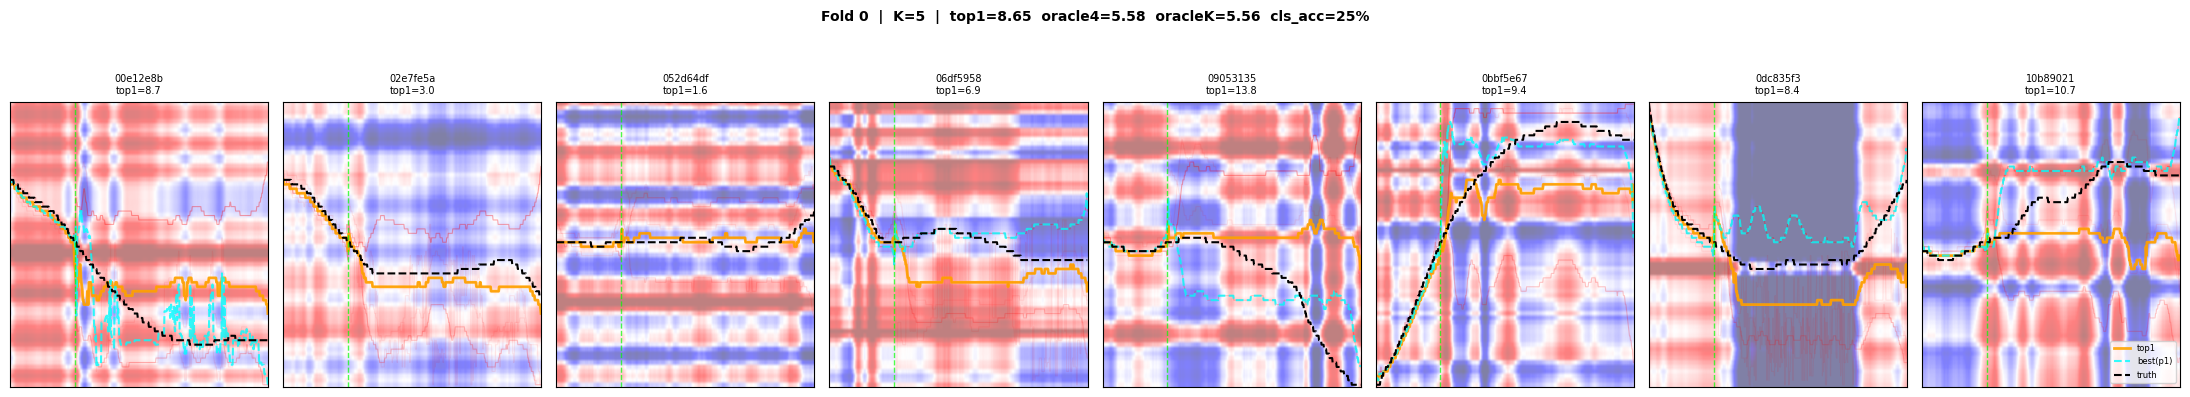


  Mode analysis (K=5):
    Mode 0: wins  1/8, mean_prob=0.195
    Mode 1: wins  0/8, mean_prob=0.000
    Mode 2: wins  4/8, mean_prob=0.303
    Mode 3: wins  2/8, mean_prob=0.502
    Mode 4: wins  1/8, mean_prob=0.000

    Top-1 RMSE   : 8.647  (highest-prob path)
    Oracle-4 RMSE: 5.582  (best of 4 returned paths)
    Oracle-K RMSE: 5.564  (best of 5 modes)
    Cls accuracy : 25.0%

  FOLD 1  |  rogii_sdf_mtp_v9_K5_fold1_ep16_rmse9.442_sdf_mtp_v9_K5_fold1.pth
  Saved rmse=9.442  epoch=16
  load_state_dict: <All keys matched successfully>


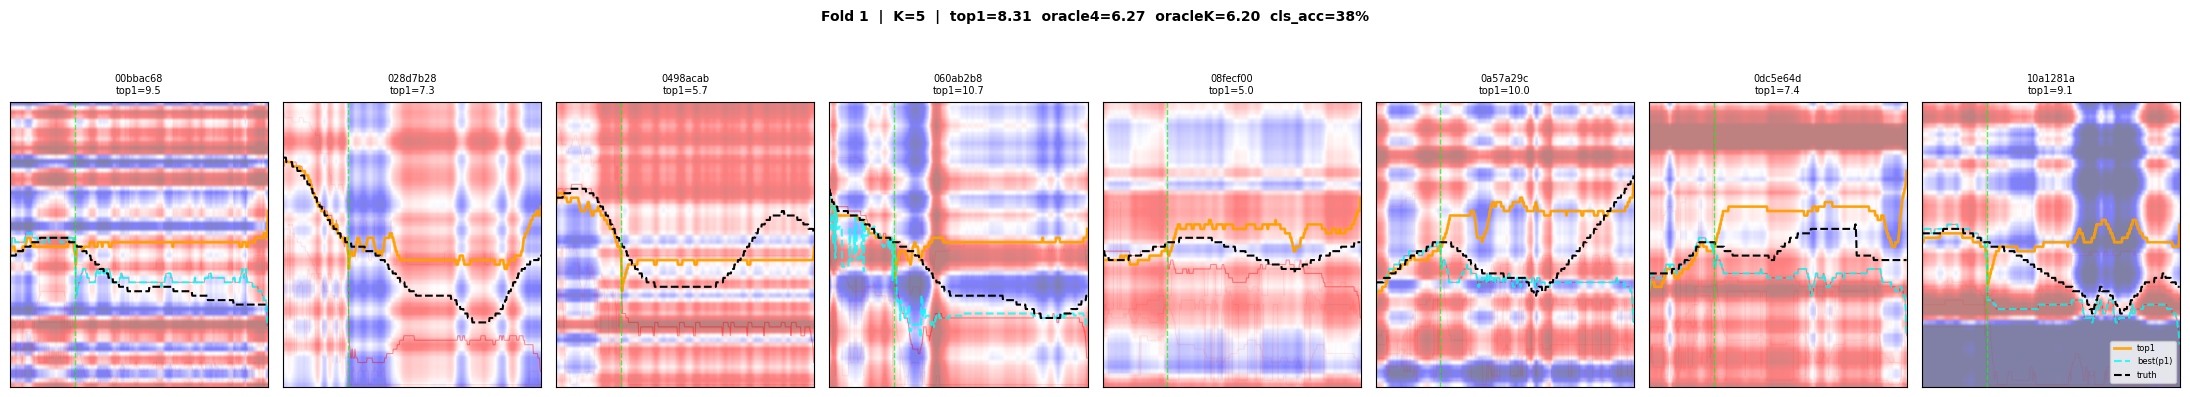


  Mode analysis (K=5):
    Mode 0: wins  0/8, mean_prob=0.000
    Mode 1: wins  3/8, mean_prob=0.595
    Mode 2: wins  5/8, mean_prob=0.405
    Mode 3: wins  0/8, mean_prob=0.000
    Mode 4: wins  0/8, mean_prob=0.000

    Top-1 RMSE   : 8.309  (highest-prob path)
    Oracle-4 RMSE: 6.274  (best of 4 returned paths)
    Oracle-K RMSE: 6.199  (best of 5 modes)
    Cls accuracy : 37.5%

  FOLD 2  |  rogii_sdf_mtp_v9_K5_fold2_ep26_rmse9.517_sdf_mtp_v9_K5_fold2.pth
  Saved rmse=9.517  epoch=26
  load_state_dict: <All keys matched successfully>


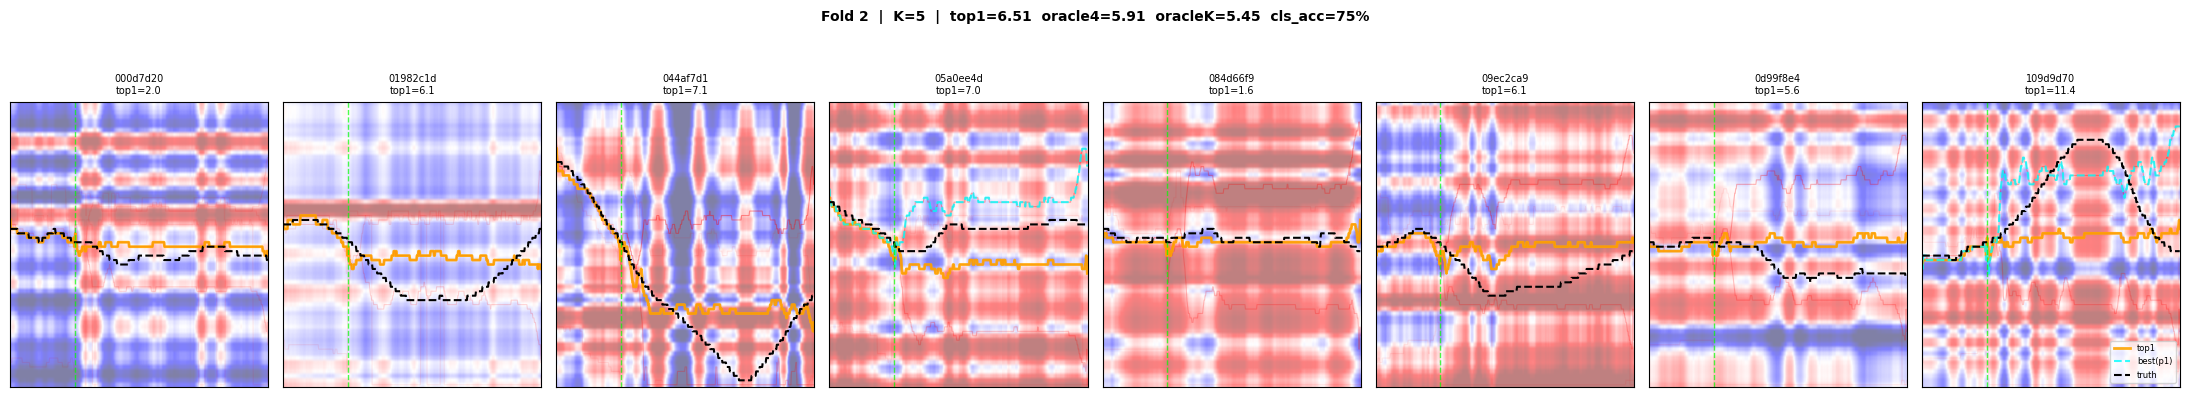


  Mode analysis (K=5):
    Mode 0: wins  0/8, mean_prob=0.203
    Mode 1: wins  6/8, mean_prob=0.538
    Mode 2: wins  0/8, mean_prob=0.000
    Mode 3: wins  2/8, mean_prob=0.259
    Mode 4: wins  0/8, mean_prob=0.000

    Top-1 RMSE   : 6.515  (highest-prob path)
    Oracle-4 RMSE: 5.915  (best of 4 returned paths)
    Oracle-K RMSE: 5.446  (best of 5 modes)
    Cls accuracy : 75.0%

  FOLD 3  |  rogii_sdf_mtp_v9_K5_fold3_ep33_rmse9.707_sdf_mtp_v9_K5_fold3.pth
  Saved rmse=9.707  epoch=33
  load_state_dict: <All keys matched successfully>


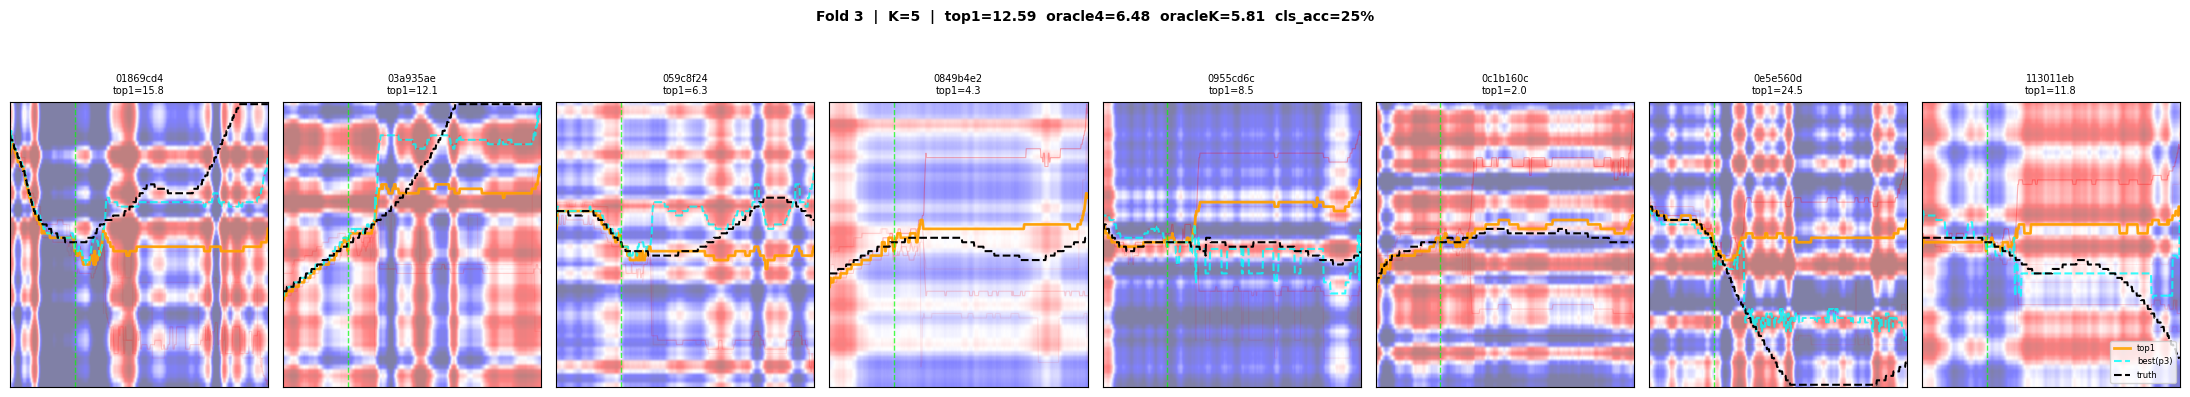


  Mode analysis (K=5):
    Mode 0: wins  1/8, mean_prob=0.163
    Mode 1: wins  2/8, mean_prob=0.000
    Mode 2: wins  3/8, mean_prob=0.294
    Mode 3: wins  0/8, mean_prob=0.000
    Mode 4: wins  2/8, mean_prob=0.543

    Top-1 RMSE   : 12.587  (highest-prob path)
    Oracle-4 RMSE: 6.483  (best of 4 returned paths)
    Oracle-K RMSE: 5.806  (best of 5 modes)
    Cls accuracy : 25.0%

  FOLD 4  |  rogii_sdf_mtp_v9_K5_fold4_ep07_rmse10.332_sdf_mtp_v9_K5_fold4.pth
  Saved rmse=10.332  epoch=7
  load_state_dict: <All keys matched successfully>


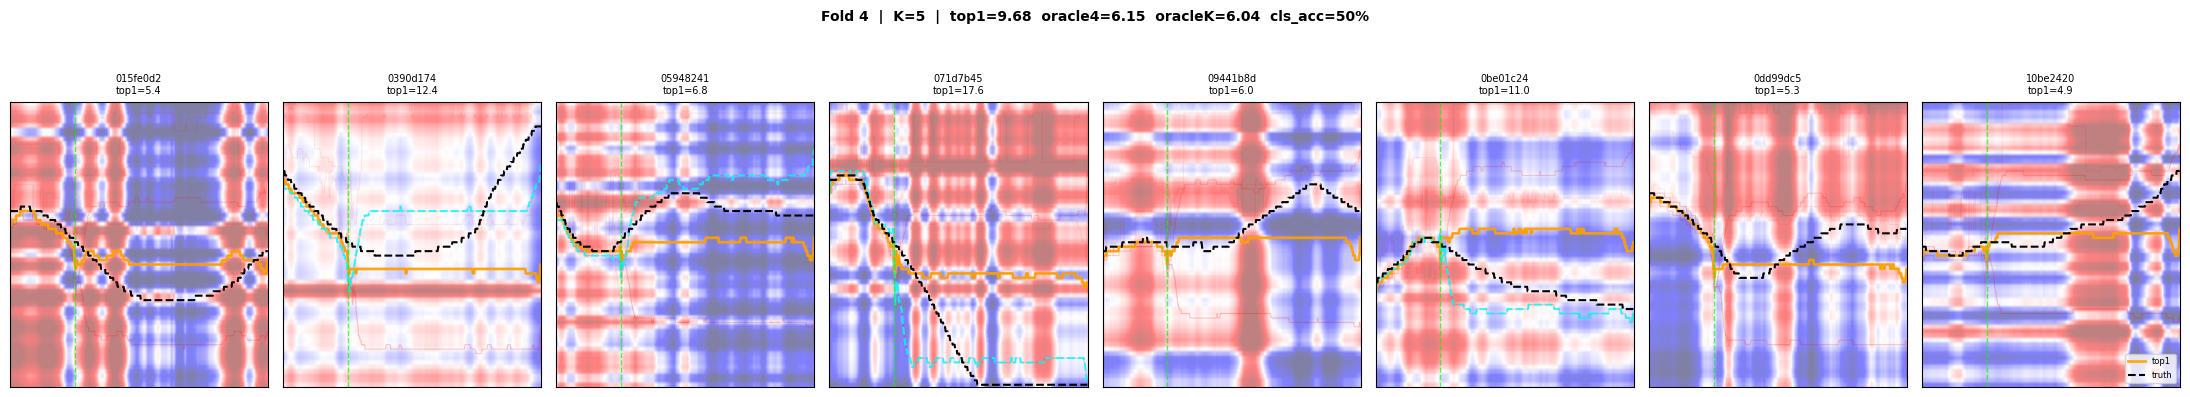


  Mode analysis (K=5):
    Mode 0: wins  0/8, mean_prob=0.000
    Mode 1: wins  2/8, mean_prob=0.186
    Mode 2: wins  2/8, mean_prob=0.213
    Mode 3: wins  0/8, mean_prob=0.001
    Mode 4: wins  4/8, mean_prob=0.600

    Top-1 RMSE   : 9.678  (highest-prob path)
    Oracle-4 RMSE: 6.147  (best of 4 returned paths)
    Oracle-K RMSE: 6.043  (best of 5 modes)
    Cls accuracy : 50.0%

  AGGREGATE SUMMARY — v9 K=5

  Per-fold Top-1 RMSE:
    Fold 0: top1=8.647  oracle4=5.582  oracleK=5.564  (8 wells)
    Fold 1: top1=8.309  oracle4=6.274  oracleK=6.199  (8 wells)
    Fold 2: top1=6.515  oracle4=5.915  oracleK=5.446  (8 wells)
    Fold 3: top1=12.587  oracle4=6.483  oracleK=5.806  (8 wells)
    Fold 4: top1=9.678  oracle4=6.147  oracleK=6.043  (8 wells)

  Aggregate (mean ± std):
    Top-1 RMSE   : 9.147 ± 2.000
    Oracle-4 RMSE: 6.080 ± 0.310
    Oracle-K RMSE: 5.812 ± 0.283
    Cls accuracy : 42.5%

  Gaps:
    top1 − oracle4 : 3.067  (classifier improvement room)
    oracle4 − oracl

In [12]:
"""
Validation visualization v9 — per-fold analysis.

Updates from v8:
  - Uses v9 dataset (t_tvt, h_tvt_history, h_history_mask; no cv2.line history)
  - Uses v9 model (5-channel image built internally, InstanceNorm, GroupNorm)
  - pred_rows is (B, 4, H): top-3 by prob + mean of 4th,5th
  - output["sdf_pred"] replaces output["sdf"]
  - Reports top1_rmse, oracle_rmse (best of 4 paths), and oracle_K (best of K modes)
"""

import os
import glob
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, "/kaggle/working")

from src.dataset import build_sample, T_TOTAL, H_TOTAL, H_H
from src.model_sdf_mtp import GeoSteerMTPNet
from src.config import CFG, RUN_VERSION

# ─────────────────────────────────────────────────────────────────────────────
# Config
# ─────────────────────────────────────────────────────────────────────────────

CHECKPOINT_DIR = "/kaggle/working/checkpoints/"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_SHOW = 8  # wells to plot per fold


# ─────────────────────────────────────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────────────────────────────────────

def parse_checkpoint_info(path):
    """Extract fold, epoch, rmse from checkpoint filename."""
    fname = os.path.basename(path)
    info = {"path": path, "fname": fname, "fold": None, "rmse": float("inf")}
    for part in fname.replace(".pth", "").split("_"):
        if part.startswith("fold"):
            try: info["fold"] = int(part.replace("fold", ""))
            except: pass
        if part.startswith("rmse"):
            try: info["rmse"] = float(part.replace("rmse", ""))
            except: pass
        if part.startswith("ep"):
            try: info["epoch"] = int(part.replace("ep", ""))
            except: pass
        if part.startswith("K"):
            try: info["K"] = int(part.replace("K", ""))
            except: pass
    return info


def find_best_per_fold(checkpoint_dir):
    """Find the best checkpoint for each fold."""
    ckpts = sorted(glob.glob(f"{checkpoint_dir}*v{RUN_VERSION}*.pth"))
    if not ckpts:
        ckpts = sorted(glob.glob(f"{checkpoint_dir}*.pth"))

    fold_best = {}
    for path in ckpts:
        info = parse_checkpoint_info(path)
        fold = info["fold"]
        if fold is None:
            continue
        if fold not in fold_best or info["rmse"] < fold_best[fold]["rmse"]:
            fold_best[fold] = info

    return fold_best


def build_batch(well_ids, device):
    """Build a batch from well IDs using v9 dataset fields."""
    fields = {
        "t_gr": [], "h_gr": [], "t_tvt": [], "h_tvt": [],
        "h_tvt_history": [], "h_mask": [], "h_history_mask": [],
        "t_mask": [], "sdf": [], "target": [],
    }
    valid_ids = []

    for wid in well_ids:
        try:
            s = build_sample(wid, split="train")
            for key in fields:
                fields[key].append(s[key])
            valid_ids.append(wid)
        except Exception as e:
            print(f"  ⚠  Skipping {wid}: {e}")

    if not valid_ids:
        return None, []

    batch = {}
    for key, arrays in fields.items():
        arr = np.stack(arrays)
        if key == "target":
            batch[key] = torch.from_numpy(arr).long().to(device)
        elif key == "sdf":
            # Add channel dim: (B, T, H) → (B, 1, T, H)
            batch[key] = torch.from_numpy(arr[:, None]).float().to(device)
        else:
            batch[key] = torch.from_numpy(arr).float().to(device)

    return batch, valid_ids


def load_model(checkpoint_path, device):
    """Load a v9 model from checkpoint."""
    ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
    state_dict = ckpt.get("model_state", ckpt)

    K = ckpt.get("K", CFG.SDF_MTP_K)
    net = GeoSteerMTPNet(
        in_ch    = 5,
        base_ch  = getattr(CFG, "SDF_MTP_BASE_CH", 32),
        K        = K,
        alpha    = getattr(CFG, "SDF_MTP_ALPHA", 0.1),
        diversity_lambda = 0.0,  # option A: no diversity penalty
    ).to(device)

    result = net.load_state_dict(state_dict, strict=False)
    print(f"  load_state_dict: {result}")
    net.eval()
    return net, K


def compute_row_rmse(pred_rows, target, h_mask):
    """Row RMSE over valid columns. pred_rows and target are 1D arrays."""
    valid = h_mask > 0.5
    if not valid.any():
        return float("nan")
    return float(np.sqrt(np.mean(
        (pred_rows[valid] - target[valid].astype(float)) ** 2
    )))


# ─────────────────────────────────────────────────────────────────────────────
# Per-fold validation
# ─────────────────────────────────────────────────────────────────────────────

def validate_fold(fold_info, valid_ids, device, n_show=8):
    """Run validation for one fold: load model, predict, visualize."""
    path = fold_info["path"]
    fold = fold_info["fold"]

    print(f"\n{'='*60}")
    print(f"  FOLD {fold}  |  {fold_info['fname']}")
    print(f"  Saved rmse={fold_info['rmse']:.3f}  epoch={fold_info.get('epoch','?')}")
    print(f"{'='*60}")

    # Load model
    net, K = load_model(path, device)

    # Build batch
    show_ids = valid_ids[:n_show]
    batch, loaded_ids = build_batch(show_ids, device)
    if batch is None:
        print("  No valid wells loaded!")
        return None

    B = len(loaded_ids)

    # Inference
    with torch.no_grad():
        output = net(batch)

    # ── Extract predictions ──────────────────────────────────────────────
    pred_rows_4 = output["pred_rows"].cpu().numpy()        # (B, 4, H)
    pred_top1   = pred_rows_4[:, 0, :]                     # (B, H) — highest prob
    sdf_pred    = output["sdf_pred"].cpu().numpy()          # (B, K, T, H)
    truth       = batch["target"].cpu().numpy()             # (B, H)
    h_mask      = batch["h_mask"].cpu().numpy()             # (B, H)

    # Per-mode boundary rows from SDF zero crossings: (B, K, H)
    mode_rows = np.abs(sdf_pred).argmin(axis=2).astype(float)

    # MTP probabilities
    if K > 1:
        prob_np = F.softmax(output["logit"], dim=1).cpu().numpy()  # (B, K)
    else:
        prob_np = np.ones((B, 1))

    # ── Metrics ──────────────────────────────────────────────────────────
    # Top-1: highest probability path
    top1_errors = []
    for b in range(B):
        valid = h_mask[b] > 0.5
        top1_errors.append((pred_top1[b][valid] - truth[b][valid]) ** 2)
    top1_rmse = float(np.sqrt(np.mean(np.concatenate(top1_errors))))

    # Oracle-4: best of the 4 returned paths per sample
    oracle4_errors = []
    for b in range(B):
        valid = h_mask[b] > 0.5
        per_path = [np.mean((pred_rows_4[b, p, valid] - truth[b][valid]) ** 2)
                    for p in range(4)]
        oracle4_errors.append(per_path[int(np.argmin(per_path))])
    oracle4_rmse = float(np.sqrt(np.mean(oracle4_errors)))

    # Oracle-K: best of ALL K modes (upper bound on MTP potential)
    oracleK_errors, best_k_all, classifier_pick = [], [], []
    for b in range(B):
        valid = h_mask[b] > 0.5
        per_mode = [np.sqrt(np.mean((mode_rows[b, k, valid] - truth[b][valid]) ** 2))
                    for k in range(K)]
        best_k = int(np.argmin(per_mode))
        best_k_all.append(best_k)
        oracleK_errors.append(per_mode[best_k])
        classifier_pick.append(int(prob_np[b].argmax()))

    oracleK_rmse = np.mean(oracleK_errors)
    cls_acc = np.mean(np.array(best_k_all) == np.array(classifier_pick))

    # ── Visualization ────────────────────────────────────────────────────
    n_plot = min(B, n_show)
    fig, axes = plt.subplots(1, n_plot, figsize=(22, 4))
    if n_plot == 1:
        axes = [axes]

    fig.suptitle(
        f"Fold {fold}  |  K={K}  |  top1={top1_rmse:.2f}  "
        f"oracle4={oracle4_rmse:.2f}  oracleK={oracleK_rmse:.2f}  "
        f"cls_acc={cls_acc:.0%}",
        fontsize=10, fontweight="bold",
    )

    for j in range(n_plot):
        ax = axes[j]

        # Background: GR misfit heatmap
        t_gr = batch["t_gr"][j].cpu().numpy()
        h_gr = batch["h_gr"][j].cpu().numpy()
        heatmap = t_gr[:, None] - h_gr[None, :]
        mask_2d = batch["t_mask"][j].cpu().numpy()[:, None] * h_mask[j][None, :]

        ax.imshow(heatmap * mask_2d, aspect="auto", cmap="seismic",
                  vmin=-40, vmax=40, alpha=0.5)

        col_idx = np.arange(H_TOTAL)
        valid = h_mask[j] > 0.5

        # All K mode trajectories (transparency ∝ probability)
        if K > 1:
            q = np.maximum(prob_np[j], 0.08)
            for k in range(K):
                ax.plot(col_idx[valid], mode_rows[j, k, valid],
                        color="red", alpha=float(q[k]), lw=0.8)

        # Top-1 prediction (orange)
        ax.plot(col_idx[valid], pred_top1[j][valid],
                color="orange", lw=2.0, alpha=0.9, label="top1")

        # Oracle-4 best path (cyan dashed)
        per_path_mse = [np.mean((pred_rows_4[j, p, valid] - truth[j][valid]) ** 2)
                        for p in range(4)]
        best_p = int(np.argmin(per_path_mse))
        if best_p != 0:
            ax.plot(col_idx[valid], pred_rows_4[j, best_p, valid],
                    color="cyan", lw=1.5, ls="--", alpha=0.8, label=f"best(p{best_p})")

        # Ground truth (black dashed)
        ax.plot(col_idx[valid], truth[j][valid], "k--", lw=1.5, label="truth")

        # PS boundary
        ax.axvline(H_H, color="lime", ls="--", lw=1, alpha=0.7)

        # Per-well RMSE
        well_rmse = compute_row_rmse(pred_top1[j], truth[j], h_mask[j])
        ax.set_title(f"{loaded_ids[j][:8]}\ntop1={well_rmse:.1f}", fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])

    # Legend on last panel
    axes[-1].legend(fontsize=6, loc="lower right")

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

    # ── Mode analysis ────────────────────────────────────────────────────
    results = {
        "fold": fold, "K": K, "n_wells": B,
        "top1_rmse": top1_rmse,
        "oracle4_rmse": oracle4_rmse,
        "oracleK_rmse": oracleK_rmse,
        "cls_accuracy": cls_acc,
    }

    if K > 1:
        print(f"\n  Mode analysis (K={K}):")
        for k in range(K):
            wins = sum(1 for bk in best_k_all if bk == k)
            mp = prob_np[:, k].mean()
            print(f"    Mode {k}: wins {wins:2d}/{B}, mean_prob={mp:.3f}")
        print(f"\n    Top-1 RMSE   : {top1_rmse:.3f}  (highest-prob path)")
        print(f"    Oracle-4 RMSE: {oracle4_rmse:.3f}  (best of 4 returned paths)")
        print(f"    Oracle-K RMSE: {oracleK_rmse:.3f}  (best of {K} modes)")
        print(f"    Cls accuracy : {cls_acc:.1%}")

    return results


# ─────────────────────────────────────────────────────────────────────────────
# Main: loop over all folds
# ─────────────────────────────────────────────────────────────────────────────

from sklearn.model_selection import GroupKFold
import pandas as pd

train_dir = CFG.TRAIN_DIR
all_hw = sorted(glob.glob(f"{train_dir}/*__horizontal_well.csv"))
all_ids = [os.path.basename(f).replace("__horizontal_well.csv", "") for f in all_hw]

groups = np.arange(len(all_ids))
gkf = GroupKFold(n_splits=CFG.N_FOLDS)
folds = list(gkf.split(all_ids, groups=groups))

fold_best = find_best_per_fold(CHECKPOINT_DIR)

print(f"Found checkpoints for folds: {sorted(fold_best.keys())}")
print(f"Total wells: {len(all_ids)}")
print()

for fold_idx, info in sorted(fold_best.items()):
    print(f"  Fold {fold_idx}: {info['fname']}  rmse={info['rmse']:.3f}")

# ── Run validation per fold ──────────────────────────────────────────────
all_results = []

for fold_idx in sorted(fold_best.keys()):
    _, val_indices = folds[fold_idx]
    valid_ids = [all_ids[i] for i in val_indices]

    result = validate_fold(
        fold_best[fold_idx],
        valid_ids,
        DEVICE,
        n_show=N_SHOW,
    )
    if result is not None:
        all_results.append(result)


# ─────────────────────────────────────────────────────────────────────────────
# Aggregate summary
# ─────────────────────────────────────────────────────────────────────────────

if all_results:
    print(f"\n{'='*60}")
    print(f"  AGGREGATE SUMMARY — v{RUN_VERSION} K={all_results[0]['K']}")
    print(f"{'='*60}")

    top1s    = [r["top1_rmse"] for r in all_results]
    oracle4s = [r["oracle4_rmse"] for r in all_results]
    oracleKs = [r["oracleK_rmse"] for r in all_results]
    cls_accs = [r["cls_accuracy"] for r in all_results]

    print(f"\n  Per-fold Top-1 RMSE:")
    for r in all_results:
        print(f"    Fold {r['fold']}: top1={r['top1_rmse']:.3f}  "
              f"oracle4={r['oracle4_rmse']:.3f}  "
              f"oracleK={r['oracleK_rmse']:.3f}  "
              f"({r['n_wells']} wells)")

    print(f"\n  Aggregate (mean ± std):")
    print(f"    Top-1 RMSE   : {np.mean(top1s):.3f} ± {np.std(top1s):.3f}")
    print(f"    Oracle-4 RMSE: {np.mean(oracle4s):.3f} ± {np.std(oracle4s):.3f}")
    print(f"    Oracle-K RMSE: {np.mean(oracleKs):.3f} ± {np.std(oracleKs):.3f}")
    print(f"    Cls accuracy : {np.mean(cls_accs):.1%}")

    print(f"\n  Gaps:")
    print(f"    top1 − oracle4 : {np.mean(top1s) - np.mean(oracle4s):.3f}  "
          f"(classifier improvement room)")
    print(f"    oracle4 − oracleK: {np.mean(oracle4s) - np.mean(oracleKs):.3f}  "
          f"(paths not in top-3+tail)")

    print(f"\n{'='*60}")